# Dengue Early-Warning for Sri Lankan Districts
### Predicting high-transmission dengue weeks two weeks ahead with tuned tree ensembles, SHAP and LIME

**Module:** Applied Machine Learning – final assignment

---
## 1. Problem statement

Dengue is Sri Lanka's biggest vector-borne disease. The 2017 epidemic caused more than 186,000 reported cases, and in 2023 more than 89,000 were reported.
The Epidemiology Unit publishes **weekly case counts for the 26 RDHS areas** (25 districts plus Kalmunai).
Regional MOH offices and Public Health Inspectors respond to rising cases with vector-control work (fogging, larval source reduction and school/community clean-up drives).
These campaigns need **lead time**, because staff, insecticide and community mobilisation have to be scheduled in advance.

**ML task (binary classification):** at the end of report week *t*, using only information available that week, predict
whether a district's dengue cases in **week *t + 2*** will be **above that district's high-transmission threshold**.
The threshold is the district's 75th percentile of weekly cases over 2012–2021.

* Positive class (`high_risk = 1`): a week of unusually high transmission for that district.
* Two-week horizon: one week covers the reporting delay and one week covers mobilisation.

Each district has its own threshold, so Colombo (where 150 cases a week is normal) and Mullaitivu (where 5 a week is normal) are judged on their own scale.

## 2. Dataset: real Sri Lankan data

| | |
|---|---|
| **Source** | Epidemiology Unit, Ministry of Health Sri Lanka – *Weekly Epidemiological Report* (district dengue notifications) |
| **Access** | Tidy version in the `denguedatahub` R package by Dr. Thiyanga S. Talagala, University of Sri Jayewardenepura (GitHub `thiyangt/denguedatahub`, object `srilanka_weekly_data`), exported to CSV |
| **Coverage** | 26 RDHS areas × weekly, 23 Dec 2006 – 17 May 2026 (26,311 rows) |
| **Columns** | `year`, `week`, `start.date`, `end.date`, `district`, `cases` |

This is a new problem for this module. It doesn't reuse the car or house price datasets that are common in other projects.

## 3. Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, balanced_accuracy_score, brier_score_loss,
                             roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import optuna, shap, lime, lime.lime_tabular

from src.features import (load_raw, clean, fit_reference, build_features, split, time_series_folds,
                          FEATURES, FEATURE_DESCRIPTIONS, HORIZON, REFERENCE_YEARS)
from src.models import PersistenceBaseline, TimeSeriesStack

SEED = 42
np.random.seed(SEED)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight")

print("numpy", np.__version__, "| pandas", pd.__version__, "| xgboost", __import__("xgboost").__version__,
      "| lightgbm", __import__("lightgbm").__version__, "| catboost", __import__("catboost").__version__,
      "| shap", shap.__version__)

numpy 2.5.3 | pandas 3.0.5 | xgboost 3.4.1 | lightgbm 4.7.0 | catboost 1.2.10 | shap 0.54.1


## 4. Load and inspect the raw data

In [2]:
raw = load_raw()
print("Shape:", raw.shape)
display(raw.head())
raw.info()

Shape: (26311, 7)


,year,week,start.date,end.date,district,cases,date
0,2006.0,52.0,12/23/2006,12/29/2006,Colombo,71.0,2006-12-23
1,2006.0,52.0,12/23/2006,12/29/2006,Gampaha,12.0,2006-12-23
2,2006.0,52.0,12/23/2006,12/29/2006,Kalutara,12.0,2006-12-23
3,2006.0,52.0,12/23/2006,12/29/2006,Kandy,20.0,2006-12-23
4,2006.0,52.0,12/23/2006,12/29/2006,Matale,4.0,2006-12-23


<class 'pandas.DataFrame'>
RangeIndex: 26311 entries, 0 to 26310
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   year        26311 non-null  float64       
 1   week        26311 non-null  float64       
 2   start.date  26311 non-null  str           
 3   end.date    26311 non-null  str           
 4   district    26311 non-null  str           
 5   cases       26311 non-null  float64       
 6   date        26311 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(3), str(3)
memory usage: 2.1 MB


In [3]:
print("Missing values per column:\n", raw.isna().sum().to_string())
print("\nDuplicate (year, week, district) rows:", raw.duplicated(["year", "week", "district"]).sum())
print("Date range:", raw["date"].min().date(), "->", raw["date"].max().date())
print("Districts:", raw["district"].nunique())
display(raw["cases"].describe().to_frame().T)
cnt = raw.groupby("district").size()
print("Rows per district (min/max):", cnt.min(), cnt.max(), "| short district:", cnt.idxmin())

Missing values per column:
 year          0
week          0
start.date    0
end.date      0
district      0
cases         0
date          0

Duplicate (year, week, district) rows: 0
Date range: 2006-12-23 -> 2026-05-11
Districts: 26


,count,mean,std,min,25%,50%,75%,max
cases,26311.0,31.681008,79.412352,0.0,2.0,9.0,29.0,2631.0


Rows per district (min/max): 1011 1012 | short district: Puttalam


In [4]:
# gaps between consecutive weeks in each district
gaps = raw.sort_values("date").groupby("district")["date"].diff().dt.days.value_counts().sort_index()
print("Days between consecutive reports:\n", gaps.to_string())

Days between consecutive reports:
 date
6.0        26
7.0     26206
8.0        26
9.0        26
14.0        1


**First observations**
* No `NaN`s and no duplicates. (The EDA below shows that the absence of `NaN`s is misleading: one district-year is recorded as zeros.) One district-week is completely missing (Puttalam, a 14-day gap). Report weeks are normally 7 days, with an occasional 6–9 day week at year boundaries.
* `cases` is a count that is **very right-skewed**: the median is 9, but the maximum is 2,631 (Colombo during the 2017 epidemic).
* The single 2006 week is a stub. The modelling period starts in 2007.

## 5. Exploratory data analysis

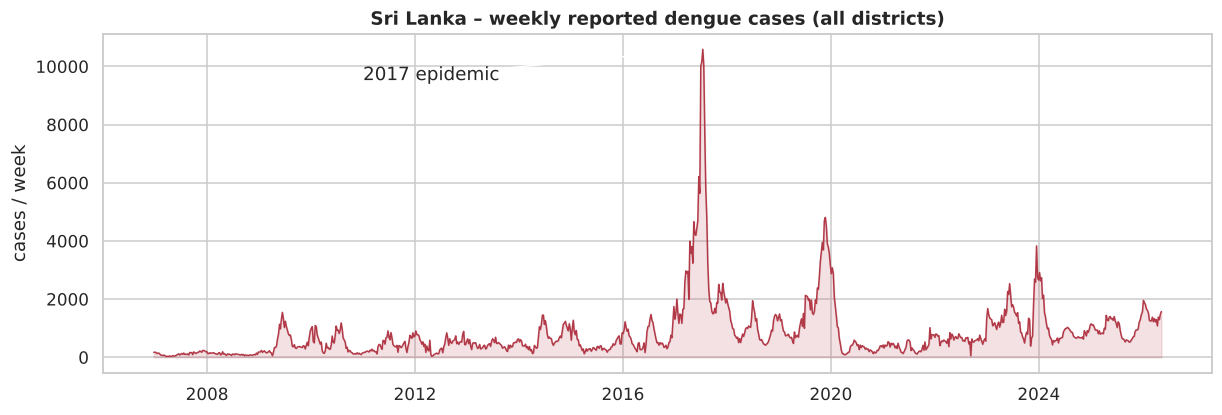

In [5]:
nat = raw.groupby("date")["cases"].sum()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(nat.index, nat.values, lw=1, color="#b23a48")
ax.fill_between(nat.index, nat.values, alpha=.15, color="#b23a48")
ax.set_title("Sri Lanka – weekly reported dengue cases (all districts)")
ax.set_ylabel("cases / week")
ax.annotate("2017 epidemic", xy=(pd.Timestamp("2017-07-01"), nat.max()), xytext=(pd.Timestamp("2011-01-01"), nat.max() * .9),
            arrowprops=dict(arrowstyle="->"))
savefig("eda_national_weekly"); plt.show()

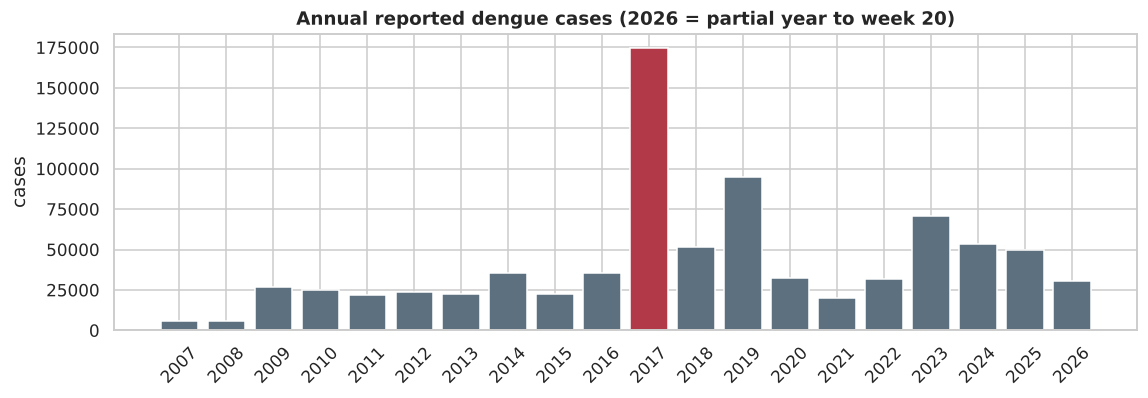

In [6]:
annual = raw[raw["year"] >= 2007].groupby("year")["cases"].sum()
fig, ax = plt.subplots(figsize=(12, 3.5))
bars = ax.bar(annual.index.astype(int).astype(str), annual.values, color=["#b23a48" if y == 2017 else "#5c7080" for y in annual.index])
ax.set_title("Annual reported dengue cases (2026 = partial year to week 20)"); ax.set_ylabel("cases")
plt.xticks(rotation=45); savefig("eda_annual"); plt.show()

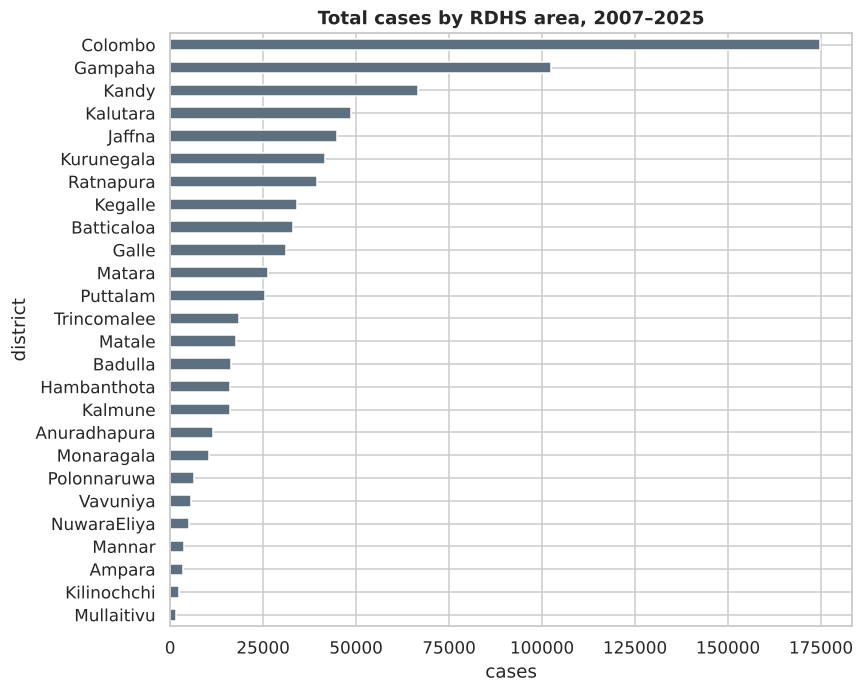

Colombo + Gampaha + Kalutara (Western Province) share: 40.5%


In [7]:
dist_tot = raw[raw["year"].between(2007, 2025)].groupby("district")["cases"].sum().sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
dist_tot.plot.barh(ax=ax, color="#5c7080")
ax.set_title("Total cases by RDHS area, 2007–2025"); ax.set_xlabel("cases")
savefig("eda_district_totals"); plt.show()
print(f"Colombo + Gampaha + Kalutara (Western Province) share: {dist_tot[['Colombo','Gampaha','Kalutara']].sum() / dist_tot.sum():.1%}")

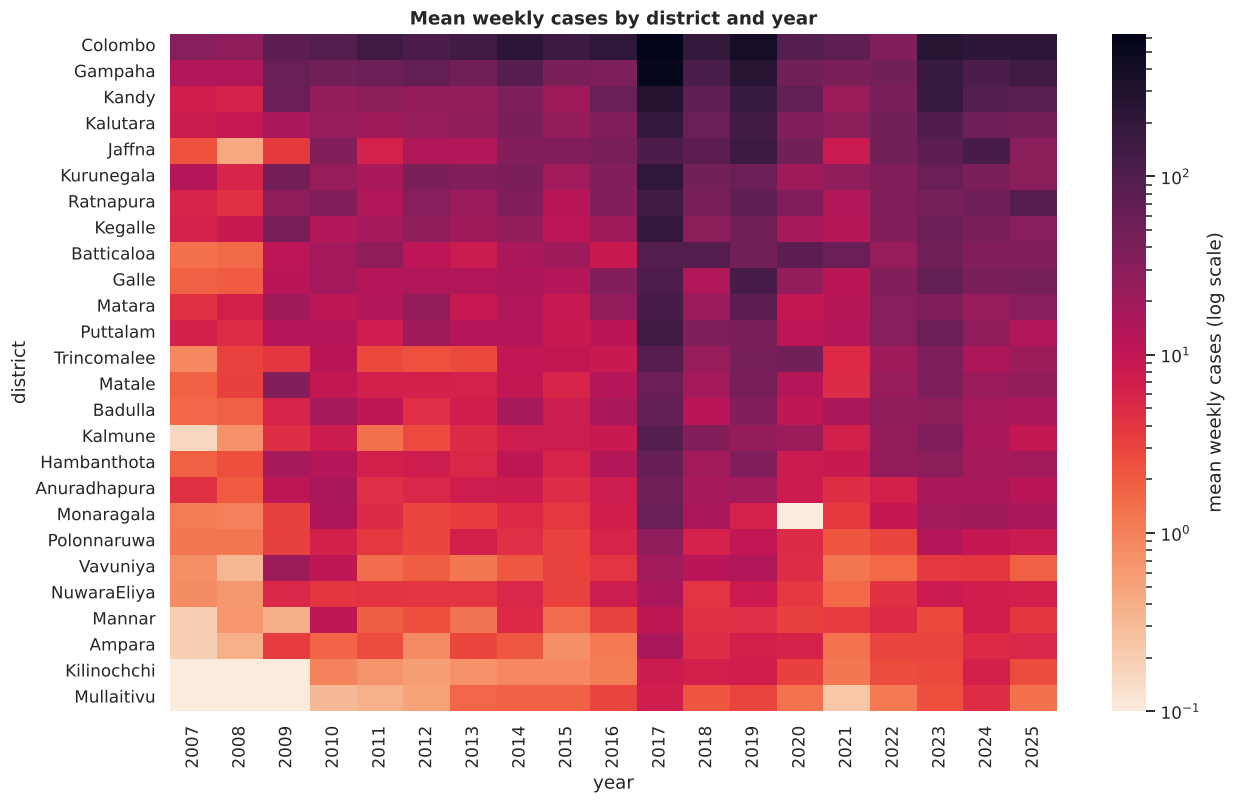

In [8]:
pivot = raw[raw["year"].between(2007, 2025)].pivot_table(index="district", columns="year", values="cases", aggfunc="mean")
pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(13, 8))
sns.heatmap(pivot + 0.1, norm=mcolors.LogNorm(), cmap="rocket_r", ax=ax, cbar_kws={"label": "mean weekly cases (log scale)"})
ax.set_xticklabels([int(float(t.get_text())) for t in ax.get_xticklabels()])
ax.set_title("Mean weekly cases by district and year")
savefig("eda_heatmap_district_year"); plt.show()

In [9]:
# Data-quality check suggested by the heatmap: district-years with (almost) no reported cases
yr_tot = raw[raw["year"].between(2009, 2025)].pivot_table(index="district", columns="year", values="cases", aggfunc="sum")
zero_years = yr_tot.stack()[lambda s: s == 0]
print("District-years with ZERO reported cases:\n", zero_years.to_string())
display(yr_tot.loc[["Monaragala"], [2018.0, 2019.0, 2020.0, 2021.0, 2022.0]])

District-years with ZERO reported cases:
 district     year  
Kilinochchi  2009.0    0.0
Monaragala   2020.0    0.0
Mullaitivu   2009.0    0.0


year,2018.0,2019.0,2020.0,2021.0,2022.0
district,,,,,
Monaragala,854.0,330.0,0.0,192.0,457.0


**Data-quality problem found.** **Monaragala reports 0 cases in every one of the 52 weeks of 2020**, compared with 330 in 2019 and 192 in 2021.
Dengue is endemic there and every neighbouring district reported cases that year, so this is a **reporting failure, with missing data recorded as zeros**.
It isn't a real absence of dengue. If left in, the model would learn that Monaragala can drop from normal levels to zero.
Handling (section 6.1): the year is set to missing, and the rows whose 52-week look-back or target week touches it are **excluded** from training and evaluation.

The near-zero counts for Kilinochchi and Mullaitivu in 2007–09 are different. Low numbers there are plausible (the end of the conflict period and small populations), and the neighbouring years are also low, so they're kept.

**Levels differ by two orders of magnitude between districts, and the whole country moves together in epidemic years** (2017, 2019, 2023).
A single threshold for all districts would make no sense. This is why the target and the features are defined **relative to each district's own normal level**.

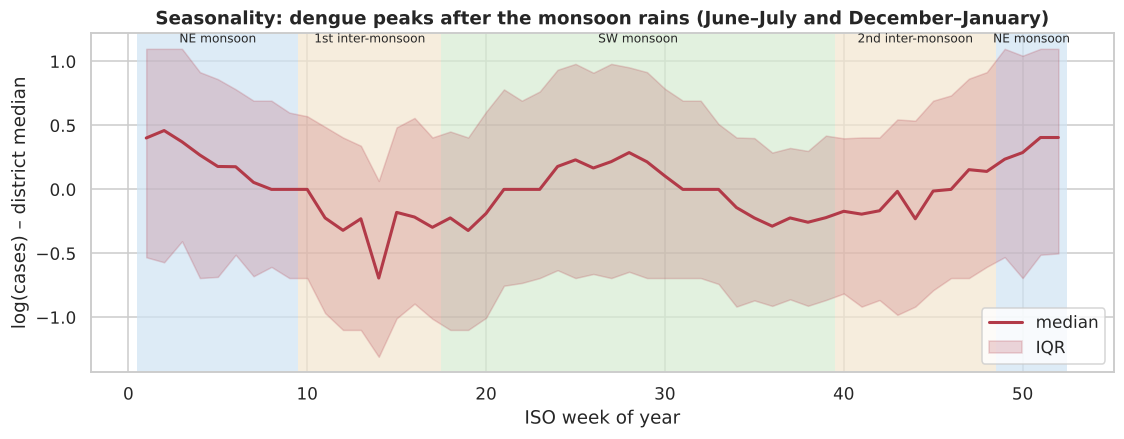

In [10]:
df = clean(raw)
df["woy"] = df["date"].dt.isocalendar().week.astype(int).clip(upper=52)
df["rel"] = np.log1p(df["cases"]) - np.log1p(df.groupby("district")["cases"].transform("median"))
season = df[df["date"].dt.year.between(2007, 2025)].groupby("woy")["rel"].agg(["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
season.columns = ["median", "q25", "q75"]
fig, ax = plt.subplots(figsize=(12, 4))
for (a, b, lab, c) in [(1, 9, "NE monsoon", "#cfe3f3"), (10, 17, "1st inter-monsoon", "#f3e6cf"), (18, 39, "SW monsoon", "#d6ecd2"), (40, 48, "2nd inter-monsoon", "#f3e6cf"), (49, 52, "NE monsoon", "#cfe3f3")]:
    ax.axvspan(a - .5, b + .5, color=c, alpha=.7, lw=0); ax.text((a + b) / 2, season["q75"].max() + .05, lab, ha="center", fontsize=8)
ax.plot(season.index, season["median"], color="#b23a48", lw=2, label="median")
ax.fill_between(season.index, season["q25"], season["q75"], color="#b23a48", alpha=.2, label="IQR")
ax.set_xlabel("ISO week of year"); ax.set_ylabel("log(cases) – district median")
ax.set_title("Seasonality: dengue peaks after the monsoon rains (June–July and December–January)"); ax.legend(loc="lower right")
savefig("eda_seasonality"); plt.show()

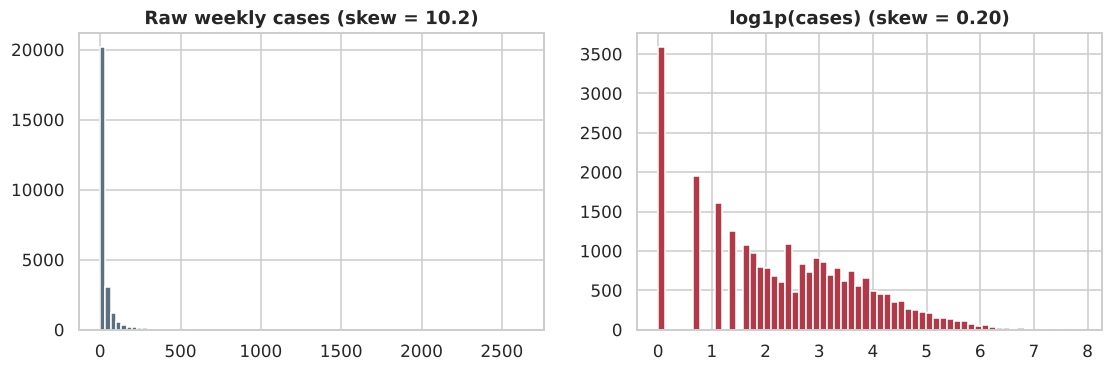

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(df["cases"], bins=80, color="#5c7080"); axes[0].set_title(f"Raw weekly cases (skew = {df['cases'].skew():.1f})")
axes[1].hist(np.log1p(df["cases"]), bins=60, color="#b23a48"); axes[1].set_title(f"log1p(cases) (skew = {np.log1p(df['cases']).skew():.2f})")
savefig("eda_distribution"); plt.show()

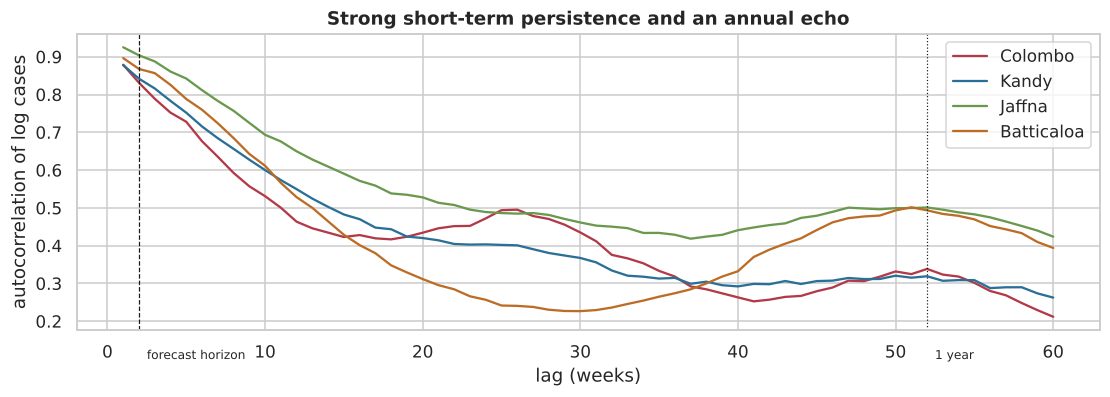

In [12]:
fig, ax = plt.subplots(figsize=(12, 3.5))
for d, c in [("Colombo", "#b23a48"), ("Kandy", "#2a6f97"), ("Jaffna", "#6a994e"), ("Batticaloa", "#bc6c25")]:
    s = np.log1p(df.loc[df["district"] == d, "cases"].reset_index(drop=True))
    ax.plot(range(1, 61), [s.autocorr(k) for k in range(1, 61)], label=d, color=c)
ax.axvline(HORIZON, ls="--", c="k", lw=.8); ax.text(HORIZON + .5, .1, "forecast horizon", fontsize=8)
ax.axvline(52, ls=":", c="k", lw=.8); ax.text(52.5, .1, "1 year", fontsize=8)
ax.set_xlabel("lag (weeks)"); ax.set_ylabel("autocorrelation of log cases"); ax.set_title("Strong short-term persistence and an annual echo")
ax.legend(); savefig("eda_autocorrelation"); plt.show()

**EDA takeaways that shape the modelling**
1. **Skewed counts.** A `log1p` transform makes the distribution near-symmetric (skew 3+ → ~0). All count features are expressed on the log scale.
2. **Strong autocorrelation.** The lag-2 autocorrelation is above 0.8, so recent weeks are the most informative. Recent lags, moving averages and growth rates are engineered as features. This also means a **persistence baseline** ("next is like now") will be hard to beat, so we report it.
3. **Monsoon seasonality and an annual echo.** Week-of-year sine/cosine terms, a seasonal norm and "same week last year" are added as features.
4. **Nationwide waves.** National growth and the share of districts above threshold are added as features.
5. **Structural change.** Levels after 2017 are higher than in 2007–2016, so a random split would leak the future. A **chronological split** with purging is used.

## 6. Preprocessing
### 6.1 Completing the time grid and imputing missing values

In [13]:
print("District-weeks after building the full grid:", len(df))
print("Imputed values (missing week + implausible values):", int(df["was_imputed"].sum()))
imp = df[df["was_imputed"] & ~df["implausible"]]
for _, r in imp.iterrows():
    ctx = df[(df["district"] == r["district"]) & (df["date"].between(r["date"] - pd.Timedelta(weeks=2), r["date"] + pd.Timedelta(weeks=2)))]
    display(ctx[["district", "date", "cases", "was_imputed"]])

District-weeks after building the full grid: 26260
Imputed values (missing week + implausible values): 23


,district,date,cases,was_imputed
23214,Puttalam,2026-01-26,26.0,False
23215,Puttalam,2026-02-02,24.0,False
23216,Puttalam,2026-02-09,25.0,True
23217,Puttalam,2026-02-16,26.0,False
23218,Puttalam,2026-02-23,30.0,False


In [14]:
print("Weeks flagged unreliable (zeros recorded for a missing year):", int(df["unreliable"].sum()),
      "->", df.loc[df["unreliable"], "district"].unique(), df.loc[df["unreliable"], "date"].dt.year.unique())

Weeks flagged unreliable (zeros recorded for a missing year): 52 -> <ArrowStringArray>
['Monaragala']
Length: 1, dtype: str [2020]


In [15]:
# Isolated implausible weeks: < 10% of BOTH neighbouring weeks (or > 10x both), neighbours >= 30 cases
raw_lookup = raw.set_index(["district", "date"])["cases"]
imp_tbl = df[df["implausible"]][["district", "date"]].copy()
g_raw = raw.sort_values("date").groupby("district")
imp_tbl["reported"] = [raw_lookup.get((d, t)) for d, t in zip(imp_tbl["district"], imp_tbl["date"])]
imp_tbl["prev week"] = [raw_lookup.get((d, t - pd.Timedelta(weeks=1))) for d, t in zip(imp_tbl["district"], imp_tbl["date"])]
imp_tbl["next week"] = [raw_lookup.get((d, t + pd.Timedelta(weeks=1))) for d, t in zip(imp_tbl["district"], imp_tbl["date"])]
imp_tbl["imputed"] = df.loc[df["implausible"], "cases"].values
print(f"Implausible isolated values: {len(imp_tbl)}")
display(imp_tbl.sort_values("date").reset_index(drop=True))
wk = raw[raw["date"] == "2026-03-30"].set_index("district")["cases"]
print("Week of 30 Mar 2026 – national total is normal (", int(wk.sum()), ") but counts are shuffled between districts:")
print(wk[["Colombo", "Gampaha", "Kalutara", "Kilinochchi", "Mannar", "Matale", "NuwaraEliya"]].to_string())

Implausible isolated values: 22


,district,date,reported,prev week,next week,imputed
0,Vavuniya,2010-01-23,2.0,55.0,30.0,42.0
1,Batticaloa,2011-10-29,3.0,58.0,40.0,49.0
2,Colombo,2012-06-09,0.0,70.0,72.0,71.0
3,Colombo,2012-07-14,0.0,99.0,206.0,152.0
4,Colombo,2012-11-03,0.0,45.0,36.0,40.0
5,Puttalam,2013-02-02,0.0,45.0,33.0,39.0
6,Badulla,2015-01-03,2.0,41.0,38.0,40.0
7,Kandy,2016-06-04,1.0,55.0,92.0,74.0
8,Galle,2016-12-10,7.0,91.0,79.0,85.0
9,Vavuniya,2020-01-04,0.0,37.0,36.0,36.0


Week of 30 Mar 2026 – national total is normal ( 1217 ) but counts are shuffled between districts:
district
Colombo          9.0
Gampaha         10.0
Kalutara        10.0
Kilinochchi    117.0
Mannar          47.0
Matale         256.0
NuwaraEliya    113.0


**Three kinds of data problem, three treatments**
* **Isolated implausible weeks (22 values):** 15 are single weeks reported as 0–7 cases between two normal weeks (for example Colombo 70 → 0 → 72), which are missed reports recorded as zero.
  The other 7 all come from the **week of 30 March 2026**. That week's national total is normal, but the counts are **misaligned between districts**: Colombo, Gampaha and Kalutara show about 10 cases, while Kilinochchi, Mannar, Matale and Nuwara Eliya show 10–30 times their normal level.
  These values are set to missing and interpolated. The rule is conservative: both neighbouring weeks must be at least 30, so genuinely small counts in low-burden districts are never touched.
* **Isolated missing week (Puttalam):** filled by **linear interpolation within the district**. Weekly counts change smoothly, so this is better than a global mean or median (that would ignore the local trend) or dropping the row (that would break the lag features for the following weeks).
* **A whole missing year (Monaragala 2020, recorded as zeros):** a year of interpolated values would be invented data, so these weeks are set to missing and interpolated only to keep the time series continuous for the *other* rows' national features.
  Every district-week whose features or target depend on them (106 rows) is **excluded** from training, CV and testing, and from the threshold and seasonal reference.

### 6.2 Outliers
Very high counts (for example the 2017 epidemic) are **real epidemics, not errors**, and they are exactly what the model must recognise. They are **kept**. Their influence is controlled by
(i) the log transform, (ii) features expressed relative to each district's threshold, and (iii) tree-based models, which split on order and are robust to extreme values.

In [16]:
lg = np.log1p(df["cases"])
q1, q3 = lg.groupby(df["district"]).transform(lambda s: s.quantile(.25)), lg.groupby(df["district"]).transform(lambda s: s.quantile(.75))
out_mask = lg > q3 + 1.5 * (q3 - q1)
print(f"Weeks flagged as upper outliers by the 1.5×IQR rule on log scale: {out_mask.sum()} ({out_mask.mean():.1%})")
print("Share of them in 2017:", f"{(df.loc[out_mask, 'date'].dt.year == 2017).mean():.0%}")

Weeks flagged as upper outliers by the 1.5×IQR rule on log scale: 99 (0.4%)
Share of them in 2017: 73%


### 6.3 Target definition: district high-transmission thresholds
The threshold for each district is its **75th percentile of weekly cases over 2012–2021**. This is computed **inside the training period only**, so no test information leaks into the target definition. The same window gives each district's typical seasonal profile.

In [17]:
ref = fit_reference(df)
thr_tbl = pd.Series(ref["threshold"]).sort_values(ascending=False).rename("threshold (cases/week)")
display(thr_tbl.to_frame().T.round(0))

,Colombo,Gampaha,Kandy,Jaffna,Kalutara,Kurunegala,Ratnapura,Batticaloa,Kegalle,Matara,...,Matale,Anuradhapura,Monaragala,Polonnaruwa,Vavuniya,NuwaraEliya,Ampara,Mannar,Kilinochchi,Mullaitivu
threshold (cases/week),291.0,115.0,73.0,64.0,64.0,59.0,49.0,48.0,37.0,35.0,...,18.0,15.0,11.0,9.0,8.0,7.0,5.0,4.0,3.0,3.0


### 6.4 Feature engineering
All features use only data **up to week *t***. Counts are put on a log scale and **divided by the district threshold**, which turns them into log ratios, so the features have the same meaning in every district and in every era.

In [18]:
feat = build_features(df.drop(columns=["woy", "rel"]), ref)
print("Rows excluded because their window touches unreliable data:", int(feat["unreliable_window"].sum()))
display(pd.DataFrame({"feature": FEATURES, "description": [FEATURE_DESCRIPTIONS[f] for f in FEATURES]}))
display(feat[["district", "date", "cases", "threshold"] + FEATURES[:6] + ["target_cases", "high_risk"]].dropna().sample(5, random_state=SEED))

Rows excluded because their window touches unreliable data: 106


,feature,description
0,rel_now,This week's cases vs district threshold (log r...
1,rel_lag1,Cases 1 week ago vs threshold (log ratio)
2,rel_lag2,Cases 2 weeks ago vs threshold (log ratio)
3,rel_lag3,Cases 3 weeks ago vs threshold (log ratio)
4,rel_ma4,4-week average vs threshold (log ratio)
5,rel_ma8,8-week average vs threshold (log ratio)
6,rel_ma12,12-week average vs threshold (log ratio)
7,rel_ma52,52-week average vs threshold (log ratio)
8,growth_1w,Week-on-week growth (log)
9,growth_4w,Growth over 4 weeks (log)


,district,date,cases,threshold,rel_now,rel_lag1,rel_lag2,rel_lag3,rel_ma4,rel_ma8,target_cases,high_risk
23506,Ratnapura,2012-04-21,14.0,49.0,-1.203973,0.019803,-1.609438,-1.021651,-0.755023,-0.693147,17.0,0.0
12406,Kegalle,2012-06-30,13.0,37.0,-0.998529,0.212561,-3.637586,-3.637586,-0.880746,-1.347580,33.0,0.0
15684,Mannar,2017-04-01,43.0,4.0,2.174752,1.029619,0.875469,0.693147,1.386294,1.367366,25.0,1.0
16954,Matale,2022-03-26,3.0,18.0,-1.558145,-0.747214,-0.641854,-1.845827,-1.072637,-0.880746,6.0,0.0
12052,Kandy,2025-01-25,80.0,73.0,0.090384,-0.160930,0.052644,-0.114410,-0.027399,-0.048452,50.0,0.0


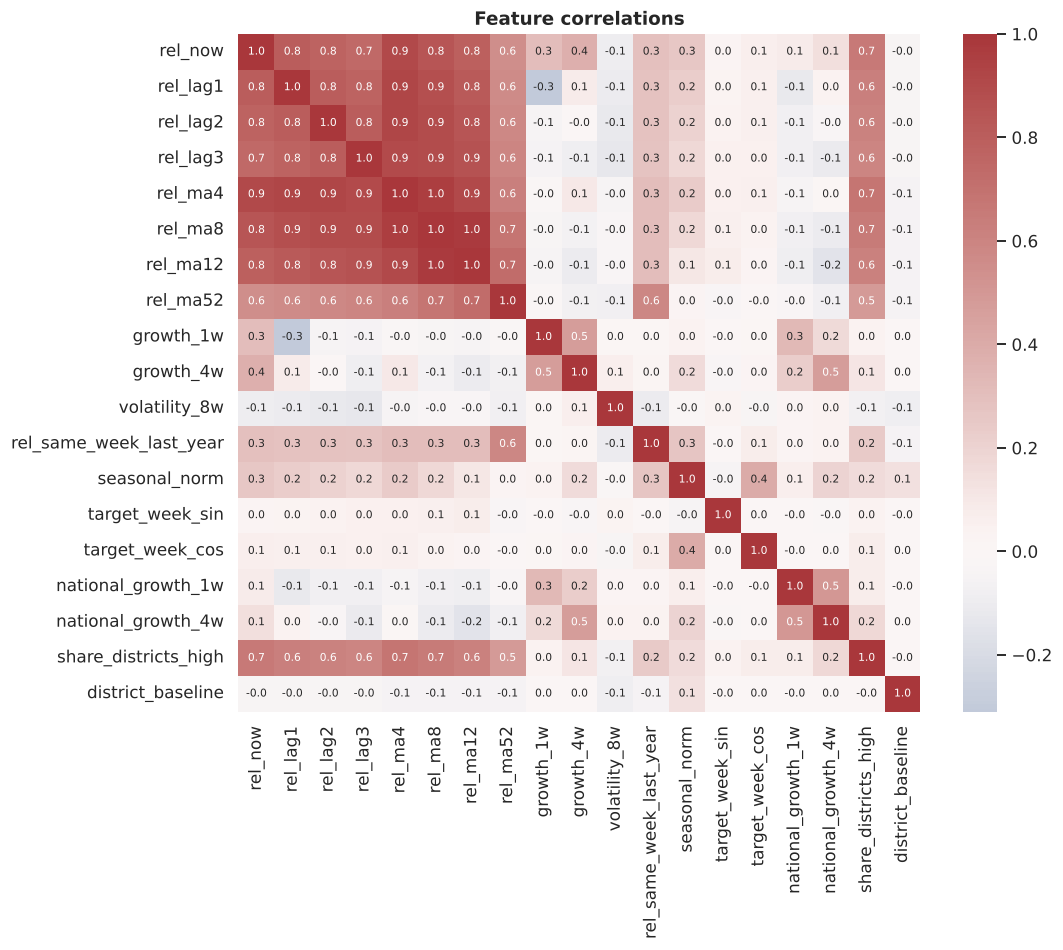

In [19]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(feat[FEATURES].dropna().corr(), cmap="vlag", center=0, ax=ax, annot=True, fmt=".1f", annot_kws={"size": 7})
ax.set_title("Feature correlations"); savefig("eda_feature_corr"); plt.show()

The lag and moving-average features are strongly correlated with each other, which is expected. Tree ensembles can handle collinear inputs. The logistic-regression baseline uses regularisation for the same reason.

### 6.5 Chronological train / validation / test split (with purging)
* **Train:** report weeks in 2007–2021 · **Validation:** 2022–2023 · **Test:** 2024 → May 2026 (never used for any decision)
* Rows whose 2-week-ahead target falls in the next period are **purged**, so no label crosses a boundary.
* Hyperparameters are tuned on the **development set** (train + validation, 2007–2023) using **expanding-window time-series cross-validation** with validation years 2019, 2020, 2021, 2022 and 2023.
* **One data point is held out entirely** (the latest Colombo week with a known outcome) for the inference demo in section 12.

In [20]:
train, valid, test = split(feat)
dev = pd.concat([train, valid]).reset_index(drop=True)
test = test.reset_index(drop=True)

# hold out a single unseen data point for the final inference demo
ho_idx = test[(test["district"] == "Colombo")]["date"].idxmax()
holdout = test.loc[[ho_idx]].copy()
test = test.drop(index=ho_idx).reset_index(drop=True)
holdout.to_csv(ROOT / "data" / "holdout_sample.csv", index=False)

X_dev, y_dev = dev[FEATURES], dev["high_risk"].astype(int).values
X_test, y_test = test[FEATURES], test["high_risk"].astype(int).values
folds = time_series_folds(dev)
oof_idx = np.concatenate([va for _, va in folds])

summary = pd.DataFrame({
    "period": ["train 2007–21", "valid 2022–23", "test 2024–26", "hold-out point"],
    "rows": [len(train), len(valid), len(test), 1],
    "positive rate": [train["high_risk"].mean(), valid["high_risk"].mean(), test["high_risk"].mean(), holdout["high_risk"].mean()],
})
display(summary.round(3))
print("CV folds (train rows, validation rows):", [(len(a), len(b)) for a, b in folds])
print("Hold-out point:", holdout[["district", "date", "target_date", "cases", "target_cases", "high_risk"]].to_dict("records"))

,period,rows,positive rate
0,train 2007–21,18850,0.197
1,valid 2022–23,2678,0.383
2,test 2024–26,3145,0.344
3,hold-out point,1,1.000


CV folds (train rows, validation rows): [(14898, 1300), (16250, 1250), (17550, 1250), (18850, 1326), (20176, 1300)]
Hold-out point: [{'district': 'Colombo', 'date': Timestamp('2026-04-27 00:00:00'), 'target_date': Timestamp('2026-05-11 00:00:00'), 'cases': 300.0, 'target_cases': 308.0, 'high_risk': 1.0}]


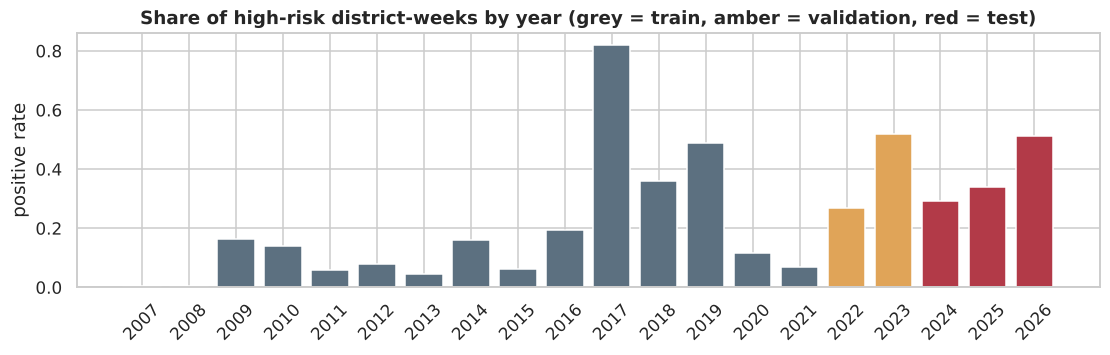

In [21]:
rate = feat.dropna(subset=["high_risk"]).groupby(feat["date"].dt.year)["high_risk"].mean()
fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(rate.index.astype(str), rate.values, color=["#5c7080" if y <= 2021 else "#e0a458" if y <= 2023 else "#b23a48" for y in rate.index])
ax.set_title("Share of high-risk district-weeks by year (grey = train, amber = validation, red = test)"); ax.set_ylabel("positive rate")
plt.xticks(rotation=45); savefig("eda_class_balance"); plt.show()

The classes are imbalanced in training (about 20% positive) and the positive rate **shifts over time** (82% in 2017, 7% in 2021). Because of this:
* **PR-AUC** (average precision) is the main tuning and selection metric. Unlike accuracy, it focuses on the positive class.
* Class weights / `scale_pos_weight` are **tuned** as hyperparameters.
* The decision threshold is chosen on the out-of-fold CV predictions, not left at 0.5.

### 6.6 Scaling
Tree models don't depend on feature scale, so they use the raw engineered features. Logistic regression uses a `StandardScaler` **inside a Pipeline**, which is fitted on each training fold only, so there's no leakage.

In [22]:
sc = StandardScaler().fit(X_dev)
print(pd.DataFrame({"mean before": X_dev.mean(), "std before": X_dev.std(),
                    "mean after": sc.transform(X_dev).mean(0), "std after": sc.transform(X_dev).std(0)}).round(2).head(8))

          mean before  std before  mean after  std after
rel_now         -0.85        1.16        -0.0        1.0
rel_lag1        -0.85        1.15         0.0        1.0
rel_lag2        -0.85        1.15        -0.0        1.0
rel_lag3        -0.86        1.15        -0.0        1.0
rel_ma4         -0.75        1.04         0.0        1.0
rel_ma8         -0.72        1.00         0.0        1.0
rel_ma12        -0.69        0.97         0.0        1.0
rel_ma52        -0.57        0.84        -0.0        1.0


## 7. Evaluation helpers and baselines

In [23]:
def metrics(y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "F1": f1_score(y, yhat), "Precision": precision_score(y, yhat, zero_division=0),
            "Recall": recall_score(y, yhat), "Bal. acc.": balanced_accuracy_score(y, yhat), "Brier": brier_score_loss(y, p)}

def cv_oof(model, X=X_dev, y=y_dev, folds=folds):
    """Fit on each expanding window and return pooled out-of-fold probabilities + per-fold PR-AUC."""
    preds, scores = [], []
    for tr, va in folds:
        m = clone(model).fit(X.iloc[tr], y[tr])
        p = m.predict_proba(X.iloc[va])[:, 1]
        preds.append(p); scores.append(average_precision_score(y[va], p))
    return np.concatenate(preds), np.array(scores)

def best_threshold(y, p):
    grid = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(y, p >= t) for t in grid]
    return float(grid[int(np.argmax(f1s))])

y_oof = y_dev[oof_idx]
fold_year = np.concatenate([[y] * len(va) for y, (_, va) in zip(range(2019, 2024), folds)])

In [24]:
baselines = {
    "Persistence (next = now)": PersistenceBaseline(),
}
cv_rows, oof_store = [], {}
for name, m in baselines.items():
    p, s = cv_oof(m); oof_store[name] = p
    cv_rows.append({"model": name, "stage": "baseline", "CV PR-AUC": s.mean(), "CV PR-AUC sd": s.std(), **{f"F1 {k}": v for k, v in [("@0.5", f1_score(y_oof, p >= .5))]}})
# seasonal naive: was the target week above threshold last year?
p_sn = (X_dev["rel_same_week_last_year"].values[oof_idx] > 0).astype(float); oof_store["Seasonal naive (last year)"] = p_sn
cv_rows.append({"model": "Seasonal naive (last year)", "stage": "baseline",
                "CV PR-AUC": np.mean([average_precision_score(y_oof[fold_year == y], p_sn[fold_year == y]) for y in range(2019, 2024)]),
                "CV PR-AUC sd": np.std([average_precision_score(y_oof[fold_year == y], p_sn[fold_year == y]) for y in range(2019, 2024)]),
                "F1 @0.5": f1_score(y_oof, p_sn >= .5)})
display(pd.DataFrame(cv_rows).round(3))

,model,stage,CV PR-AUC,CV PR-AUC sd,F1 @0.5
0,Persistence (next = now),baseline,0.577,0.159,0.742
1,Seasonal naive (last year),baseline,0.301,0.199,0.328


## 8. Models with default hyperparameters (reference point only)
These are trained **only to show the effect of tuning**. None of them is a candidate for the final model.

In [25]:
default_models = {
    "Logistic Regression": Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]),
    "Random Forest": RandomForestClassifier(random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss"),
    "LightGBM": LGBMClassifier(random_state=SEED, verbose=-1),
    "CatBoost": CatBoostClassifier(random_seed=SEED, verbose=0, thread_count=-1),
}
default_scores = {}
for name, m in default_models.items():
    t0 = time.time(); p, s = cv_oof(m)
    default_scores[name] = s.mean()
    cv_rows.append({"model": name, "stage": "default", "CV PR-AUC": s.mean(), "CV PR-AUC sd": s.std(), "F1 @0.5": f1_score(y_oof, p >= .5)})
    print(f"{name:20s} default CV PR-AUC = {s.mean():.4f}  ({time.time()-t0:.0f}s)")

Logistic Regression  default CV PR-AUC = 0.7782  (0s)


Random Forest        default CV PR-AUC = 0.7720  (11s)


XGBoost              default CV PR-AUC = 0.7535  (1s)


LightGBM             default CV PR-AUC = 0.7773  (1s)


CatBoost             default CV PR-AUC = 0.7764  (26s)


## 9. Hyperparameter tuning (Optuna, Bayesian TPE search, time-series CV)

Every model gets a search space designed for this problem. **Objective = mean PR-AUC over the five expanding-window folds.**
Key design choices:
* **Shallow trees, strong leaf constraints** (`min_child_samples`, `min_samples_leaf`, `min_child_weight`) and **L1/L2 penalties**. There are only about 20k rows, the features are noisy, and the regime changes between years, so overfitting is the main risk.
* **Row and column subsampling**, which decorrelates trees and helps with collinear lag features.
* **Class weighting** (`class_weight`, `scale_pos_weight`, `auto_class_weights`) is searched, because the positive rate varies a lot.
* A low learning rate paired with more trees.

In [26]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
spw_max = 3.0

def lr_space(t):
    return Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(
        C=t.suggest_float("C", 1e-3, 10, log=True), l1_ratio=t.suggest_categorical("l1_ratio", [0.0, 0.5, 1.0]),
        solver="saga", class_weight=t.suggest_categorical("class_weight", [None, "balanced"]), max_iter=3000))])

def rf_space(t):
    return RandomForestClassifier(
        n_estimators=t.suggest_int("n_estimators", 200, 500, step=100), max_depth=t.suggest_int("max_depth", 4, 16),
        min_samples_leaf=t.suggest_int("min_samples_leaf", 5, 100, log=True),
        max_features=t.suggest_categorical("max_features", ["sqrt", 0.3, 0.5, 0.8]),
        max_samples=t.suggest_float("max_samples", 0.3, 0.9),
        class_weight=t.suggest_categorical("class_weight", [None, "balanced_subsample"]), n_jobs=-1, random_state=SEED)

def xgb_space(t):
    return XGBClassifier(
        n_estimators=t.suggest_int("n_estimators", 200, 900, step=50), learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
        max_depth=t.suggest_int("max_depth", 2, 7), min_child_weight=t.suggest_float("min_child_weight", 1, 30, log=True),
        subsample=t.suggest_float("subsample", 0.5, 1.0), colsample_bytree=t.suggest_float("colsample_bytree", 0.4, 1.0),
        gamma=t.suggest_float("gamma", 0, 5), reg_lambda=t.suggest_float("reg_lambda", 1e-2, 20, log=True),
        reg_alpha=t.suggest_float("reg_alpha", 1e-3, 5, log=True), scale_pos_weight=t.suggest_float("scale_pos_weight", 1, spw_max),
        tree_method="hist", eval_metric="logloss", n_jobs=-1, random_state=SEED)

def lgbm_space(t):
    return LGBMClassifier(
        n_estimators=t.suggest_int("n_estimators", 200, 900, step=50), learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=t.suggest_int("num_leaves", 4, 64, log=True), max_depth=t.suggest_int("max_depth", 3, 10),
        min_child_samples=t.suggest_int("min_child_samples", 10, 300, log=True),
        subsample=t.suggest_float("subsample", 0.5, 1.0), subsample_freq=1, colsample_bytree=t.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=t.suggest_float("reg_lambda", 1e-3, 20, log=True), reg_alpha=t.suggest_float("reg_alpha", 1e-3, 5, log=True),
        scale_pos_weight=t.suggest_float("scale_pos_weight", 1, spw_max), random_state=SEED, verbose=-1, n_jobs=-1)

def cat_space(t):
    return CatBoostClassifier(
        iterations=t.suggest_int("iterations", 300, 900, step=100), learning_rate=t.suggest_float("learning_rate", 0.02, 0.2, log=True),
        depth=t.suggest_int("depth", 3, 8), l2_leaf_reg=t.suggest_float("l2_leaf_reg", 1, 30, log=True),
        random_strength=t.suggest_float("random_strength", 0.1, 5, log=True), bagging_temperature=t.suggest_float("bagging_temperature", 0, 1),
        auto_class_weights=t.suggest_categorical("auto_class_weights", ["None", "SqrtBalanced", "Balanced"]),
        random_seed=SEED, verbose=0, thread_count=-1)

spaces = {"Logistic Regression": (lr_space, 15), "Random Forest": (rf_space, 20), "XGBoost": (xgb_space, 30),
          "LightGBM": (lgbm_space, 30), "CatBoost": (cat_space, 20)}

studies, tuned = {}, {}
for name, (space, n_trials) in spaces.items():
    t0 = time.time()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name=name)
    study.optimize(lambda t: cv_oof(space(t))[1].mean(), n_trials=n_trials)
    studies[name] = study
    tuned[name] = space(optuna.trial.FixedTrial(study.best_params))
    print(f"{name:20s} best CV PR-AUC = {study.best_value:.4f}  (default {default_scores[name]:.4f}) | {n_trials} trials, {time.time()-t0:.0f}s")

best_params = {n: s.best_params for n, s in studies.items()}
json.dump(best_params, open(MODELS / "best_params.json", "w"), indent=2, default=str)
best_params

Logistic Regression  best CV PR-AUC = 0.7792  (default 0.7782) | 15 trials, 20s


Random Forest        best CV PR-AUC = 0.7852  (default 0.7720) | 20 trials, 602s


XGBoost              best CV PR-AUC = 0.7863  (default 0.7535) | 30 trials, 112s


LightGBM             best CV PR-AUC = 0.7869  (default 0.7773) | 30 trials, 95s


CatBoost             best CV PR-AUC = 0.7851  (default 0.7764) | 20 trials, 353s


{'Logistic Regression': {'C': 0.21846820048287902,
  'l1_ratio': 0.0,
  'class_weight': None},
 'Random Forest': {'n_estimators': 400,
  'max_depth': 6,
  'min_samples_leaf': 13,
  'max_features': 0.5,
  'max_samples': 0.6707636611684187,
  'class_weight': None},
 'XGBoost': {'n_estimators': 400,
  'learning_rate': 0.013103345931982171,
  'max_depth': 4,
  'min_child_weight': 3.018461061702051,
  'subsample': 0.675684878296412,
  'colsample_bytree': 0.7984024448667217,
  'gamma': 0.8296159137938902,
  'reg_lambda': 0.05563715584088754,
  'reg_alpha': 0.3569778474811914,
  'scale_pos_weight': 1.6275368744947503},
 'LightGBM': {'n_estimators': 500,
  'learning_rate': 0.01017647252942279,
  'num_leaves': 4,
  'max_depth': 8,
  'min_child_samples': 206,
  'subsample': 0.959425024012944,
  'colsample_bytree': 0.5281062545257524,
  'reg_lambda': 0.002271814736990715,
  'reg_alpha': 0.0049949387914562625,
  'scale_pos_weight': 2.8403707315832047},
 'CatBoost': {'iterations': 600,
  'learning_

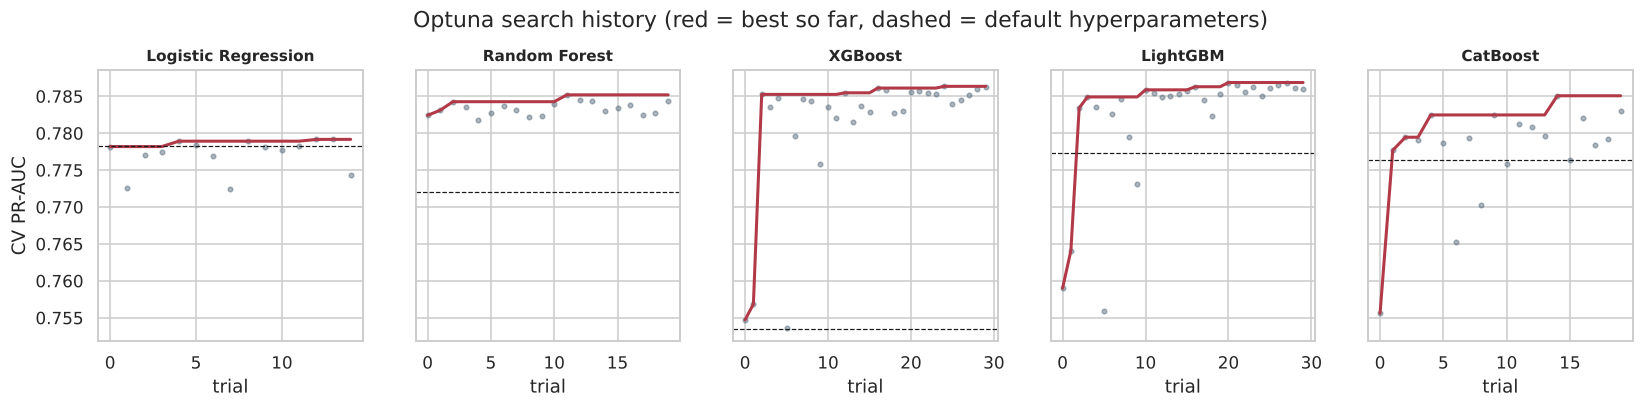

In [27]:
fig, axes = plt.subplots(1, len(studies), figsize=(18, 3.2), sharey=True)
for ax, (name, st) in zip(axes, studies.items()):
    v = [t.value for t in st.trials]
    ax.plot(v, "o", ms=3, alpha=.5, color="#5c7080"); ax.plot(np.maximum.accumulate(v), color="#b23a48", lw=2)
    ax.axhline(default_scores[name], ls="--", c="k", lw=.8); ax.set_title(name, fontsize=10); ax.set_xlabel("trial")
axes[0].set_ylabel("CV PR-AUC"); fig.suptitle("Optuna search history (red = best so far, dashed = default hyperparameters)", y=1.05)
savefig("tuning_history"); plt.show()

In [28]:
imp_rows = []
for name in ["XGBoost", "LightGBM", "CatBoost"]:
    try:
        imp = optuna.importance.get_param_importances(studies[name])
        imp_rows += [{"model": name, "hyperparameter": k, "importance": v} for k, v in list(imp.items())[:5]]
    except Exception as e:
        print(name, e)
display(pd.DataFrame(imp_rows).round(3))

,model,hyperparameter,importance
0,XGBoost,reg_lambda,0.283
1,XGBoost,learning_rate,0.274
2,XGBoost,reg_alpha,0.130
3,XGBoost,scale_pos_weight,0.118
4,XGBoost,min_child_weight,0.067
5,LightGBM,reg_alpha,0.363
6,LightGBM,learning_rate,0.208
7,LightGBM,reg_lambda,0.144
8,LightGBM,max_depth,0.085
9,LightGBM,n_estimators,0.069


## 10. Tuned models + time-series stacking ensemble

In [29]:
for name, m in tuned.items():
    p, s = cv_oof(m); oof_store[name] = p
    cv_rows.append({"model": name, "stage": "tuned", "CV PR-AUC": s.mean(), "CV PR-AUC sd": s.std(), "F1 @0.5": f1_score(y_oof, p >= .5)})

# Stacking: meta logistic regression on base-model out-of-fold probabilities.
# To score it honestly, the meta-learner for year Y is trained only on OOF predictions from years < Y.
stack_bases = ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]
Z = np.column_stack([TimeSeriesStack._logit(oof_store[n]) for n in stack_bases])
p_stack = np.full(len(y_oof), np.nan)
for y in range(2020, 2024):
    tr, va = fold_year < y, fold_year == y
    p_stack[va] = LogisticRegression(max_iter=1000).fit(Z[tr], y_oof[tr]).predict_proba(Z[va])[:, 1]
m20 = fold_year >= 2020
cv_rows.append({"model": "Stacking (RF+XGB+LGBM+Cat → LR)", "stage": "tuned",
                "CV PR-AUC": np.mean([average_precision_score(y_oof[fold_year == y], p_stack[fold_year == y]) for y in range(2020, 2024)]),
                "CV PR-AUC sd": np.std([average_precision_score(y_oof[fold_year == y], p_stack[fold_year == y]) for y in range(2020, 2024)]),
                "F1 @0.5": f1_score(y_oof[m20], p_stack[m20] >= .5)})
oof_store["Stacking (RF+XGB+LGBM+Cat → LR)"] = p_stack

# fair comparison on identical folds (2020–2023), because the stack needs 2019 to train its meta-learner
def cv_2020plus(p):
    return np.mean([average_precision_score(y_oof[fold_year == y], p[fold_year == y]) for y in range(2020, 2024)])

cv_tbl = pd.DataFrame(cv_rows)
cv_tbl["CV PR-AUC (2020–23 folds)"] = [cv_2020plus(oof_store[m]) if (m in oof_store and s != "default") else np.nan for m, s in zip(cv_tbl["model"], cv_tbl["stage"])]
display(cv_tbl.round(4))

,model,stage,CV PR-AUC,CV PR-AUC sd,F1 @0.5,CV PR-AUC (2020–23 folds)
0,Persistence (next = now),baseline,0.5771,0.1585,0.7420,0.5363
1,Seasonal naive (last year),baseline,0.3013,0.1992,0.3276,0.2582
2,Logistic Regression,default,0.7782,0.1437,0.7249,NaN
3,Random Forest,default,0.7720,0.1488,0.7370,NaN
4,XGBoost,default,0.7535,0.1613,0.7292,NaN
5,LightGBM,default,0.7773,0.1471,0.7398,NaN
6,CatBoost,default,0.7764,0.1537,0.7405,NaN
7,Logistic Regression,tuned,0.7792,0.1426,0.7238,0.7432
8,Random Forest,tuned,0.7852,0.1406,0.7375,0.7496
9,XGBoost,tuned,0.7863,0.1397,0.7588,0.7510


### 10.1 Default vs tuned

stage,default,tuned,gain
model,,,
CatBoost,0.7764,0.7851,0.0087
LightGBM,0.7773,0.7869,0.0096
Logistic Regression,0.7782,0.7792,0.0009
Random Forest,0.7720,0.7852,0.0132
XGBoost,0.7535,0.7863,0.0329


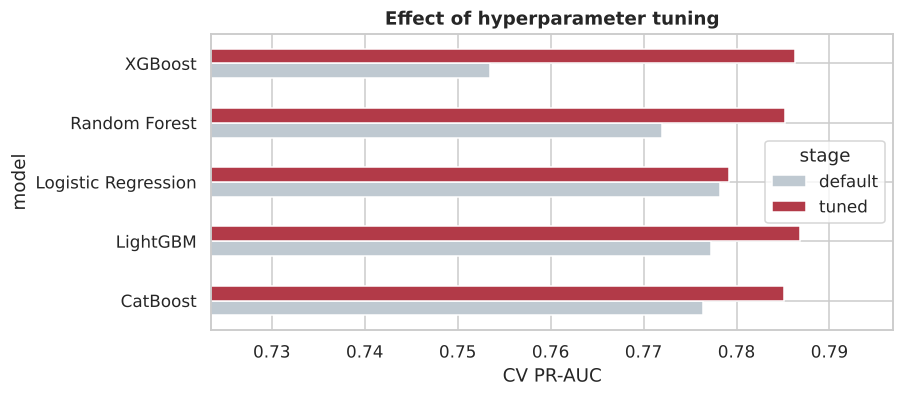

In [30]:
dvt = cv_tbl[cv_tbl["stage"].isin(["default", "tuned"]) & cv_tbl["model"].isin(default_models)].pivot(index="model", columns="stage", values="CV PR-AUC")
dvt["gain"] = dvt["tuned"] - dvt["default"]
display(dvt.round(4))
ax = dvt[["default", "tuned"]].plot.barh(figsize=(8, 3.5), color=["#bfc9d1", "#b23a48"])
ax.set_xlim(dvt[["default", "tuned"]].values.min() - .03, dvt[["default", "tuned"]].values.max() + .01)
ax.set_xlabel("CV PR-AUC"); ax.set_title("Effect of hyperparameter tuning"); savefig("default_vs_tuned"); plt.show()

### 10.2 Decision thresholds and model selection
Each model's decision threshold is set to the value that **maximises F1 on its pooled out-of-fold CV predictions**. The test set is never used for this.

**Selection rule (fixed before looking at the test set):** pick the model with the highest CV PR-AUC on the shared 2020–23 folds. If the stacking ensemble beats the best single model by **less than 0.005**, prefer the single model, because it's simpler, faster to serve and gets exact TreeSHAP explanations.

In [31]:
cands = ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM", "CatBoost", "Stacking (RF+XGB+LGBM+Cat → LR)"]
thresholds = {}
for n in cands:
    p = oof_store[n]; mask = ~np.isnan(p)
    thresholds[n] = best_threshold(y_oof[mask], p[mask])
thresholds["Persistence (next = now)"] = 0.5
thresholds["Seasonal naive (last year)"] = 0.5

sel = cv_tbl[(cv_tbl["stage"] == "tuned")].set_index("model")["CV PR-AUC (2020–23 folds)"]
best_single = sel.drop("Stacking (RF+XGB+LGBM+Cat → LR)").idxmax()
stack_gain = sel["Stacking (RF+XGB+LGBM+Cat → LR)"] - sel[best_single]
SELECTED = "Stacking (RF+XGB+LGBM+Cat → LR)" if stack_gain >= 0.005 else best_single
print(sel.sort_values(ascending=False).round(4).to_string())
print(f"\nBest single model: {best_single} | stacking gain = {stack_gain:+.4f}")
print(f"SELECTED MODEL: {SELECTED}  (decision threshold = {thresholds[SELECTED]:.2f})")

model
LightGBM                           0.7520
XGBoost                            0.7510
Random Forest                      0.7496
CatBoost                           0.7493
Stacking (RF+XGB+LGBM+Cat → LR)    0.7487
Logistic Regression                0.7432

Best single model: LightGBM | stacking gain = -0.0032
SELECTED MODEL: LightGBM  (decision threshold = 0.59)


## 11. Final evaluation on the untouched test set (Jan 2024 – May 2026)
All tuned models are refit on the full development set (2007–2023) and scored **once** on the test period.

In [32]:
final_models = {n: clone(tuned[n]).fit(X_dev, y_dev) for n in ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM", "CatBoost"]}
final_models["Stacking (RF+XGB+LGBM+Cat → LR)"] = TimeSeriesStack({n: tuned[n] for n in stack_bases}, folds).fit(X_dev, y_dev)
final_models["Persistence (next = now)"] = PersistenceBaseline().fit(X_dev, y_dev)

test_pred = {n: m.predict_proba(X_test)[:, 1] for n, m in final_models.items()}
test_pred["Seasonal naive (last year)"] = (X_test["rel_same_week_last_year"].values > 0).astype(float)

res = pd.DataFrame({n: metrics(y_test, p, thresholds[n]) for n, p in test_pred.items()}).T
res["threshold"] = [thresholds[n] for n in res.index]
res = res.sort_values("PR-AUC", ascending=False)
display(res.round(3).style.highlight_max(subset=["ROC-AUC", "PR-AUC", "F1", "Bal. acc."], color="#f6d5d9").highlight_min(subset=["Brier"], color="#f6d5d9"))
res.round(4).to_csv(ROOT / "reports" / "test_results.csv")

,ROC-AUC,PR-AUC,F1,Precision,Recall,Bal. acc.,Brier,threshold
Stacking (RF+XGB+LGBM+Cat → LR),0.888000,0.816000,0.743000,0.660000,0.850000,0.810000,0.127000,0.320000
CatBoost,0.887000,0.813000,0.737000,0.696000,0.783000,0.802000,0.167000,0.680000
Random Forest,0.882000,0.804000,0.731000,0.655000,0.826000,0.799000,0.131000,0.320000
XGBoost,0.882000,0.803000,0.735000,0.667000,0.817000,0.802000,0.136000,0.460000
LightGBM,0.877000,0.791000,0.724000,0.656000,0.807000,0.792000,0.164000,0.590000
Logistic Regression,0.875000,0.787000,0.705000,0.693000,0.717000,0.775000,0.137000,0.400000
Persistence (next = now),0.772000,0.592000,0.701000,0.695000,0.706000,0.772000,0.208000,0.500000
Seasonal naive (last year),0.585000,0.394000,0.472000,0.442000,0.506000,0.585000,0.390000,0.500000


In [33]:
# Block bootstrap over weeks (all 26 districts of a week resampled together) for 95% confidence intervals
rng = np.random.default_rng(SEED)
weeks = test["date"].values; uw = np.unique(weeks); widx = {w: np.where(weeks == w)[0] for w in uw}
boot = {n: [] for n in cands + ["Persistence (next = now)"]}
for _ in range(500):
    ii = np.concatenate([widx[w] for w in rng.choice(uw, len(uw), replace=True)])
    for n in boot:
        boot[n].append((average_precision_score(y_test[ii], test_pred[n][ii]), f1_score(y_test[ii], test_pred[n][ii] >= thresholds[n])))
ci = pd.DataFrame({n: {"PR-AUC 95% CI": f"{np.percentile([b[0] for b in v], 2.5):.3f} – {np.percentile([b[0] for b in v], 97.5):.3f}",
                       "F1 95% CI": f"{np.percentile([b[1] for b in v], 2.5):.3f} – {np.percentile([b[1] for b in v], 97.5):.3f}"} for n, v in boot.items()}).T
sel_boot = np.array(boot[SELECTED]); per_boot = np.array(boot["Persistence (next = now)"])
print(f"P(selected F1 > persistence F1) over bootstrap = {(sel_boot[:,1] > per_boot[:,1]).mean():.3f}")
display(ci)

P(selected F1 > persistence F1) over bootstrap = 0.996


,PR-AUC 95% CI,F1 95% CI
Logistic Regression,0.749 – 0.823,0.669 – 0.736
Random Forest,0.769 – 0.838,0.700 – 0.758
XGBoost,0.768 – 0.835,0.704 – 0.764
LightGBM,0.753 – 0.827,0.694 – 0.753
CatBoost,0.779 – 0.844,0.706 – 0.765
Stacking (RF+XGB+LGBM+Cat → LR),0.781 – 0.846,0.713 – 0.770
Persistence (next = now),0.547 – 0.635,0.667 – 0.734


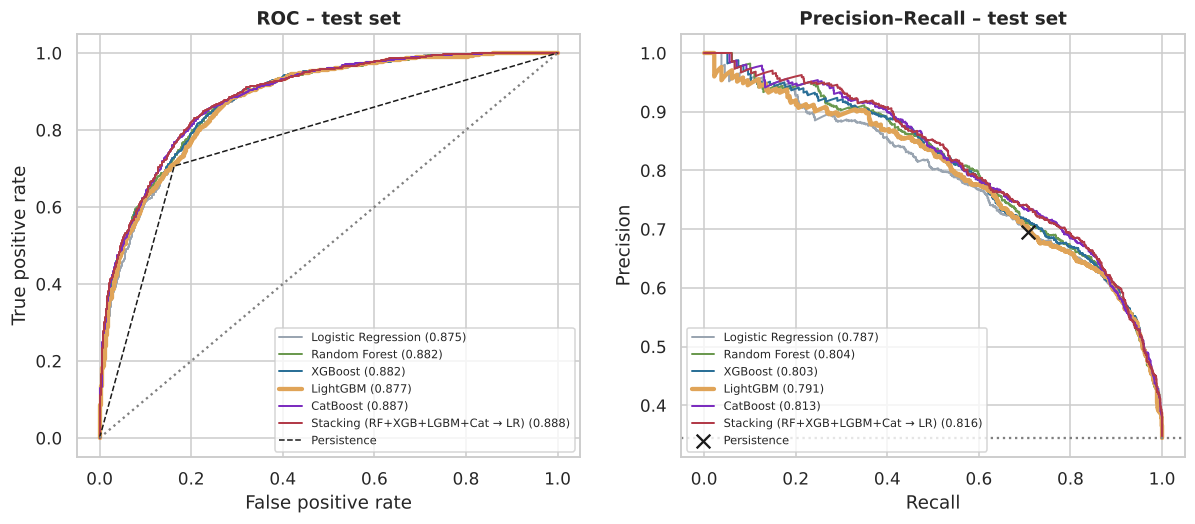

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
pal = dict(zip(cands, ["#9aa5b1", "#6a994e", "#2a6f97", "#e0a458", "#7b2cbf", "#b23a48"]))
for n in cands:
    fpr, tpr, _ = roc_curve(y_test, test_pred[n]); pr, rc, _ = precision_recall_curve(y_test, test_pred[n])
    lw = 2.8 if n == SELECTED else 1.3
    axes[0].plot(fpr, tpr, lw=lw, color=pal[n], label=f"{n} ({roc_auc_score(y_test, test_pred[n]):.3f})")
    axes[1].plot(rc, pr, lw=lw, color=pal[n], label=f"{n} ({average_precision_score(y_test, test_pred[n]):.3f})")
pp = test_pred["Persistence (next = now)"]
axes[0].plot(*roc_curve(y_test, pp)[:2], "k--", lw=1, label="Persistence"); axes[1].scatter(recall_score(y_test, pp), precision_score(y_test, pp), c="k", marker="x", s=80, label="Persistence", zorder=5)
axes[0].plot([0, 1], [0, 1], ":", c="grey"); axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC – test set")
axes[1].axhline(y_test.mean(), ls=":", c="grey"); axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–Recall – test set")
for a in axes: a.legend(fontsize=7.5, loc="lower right" if a is axes[0] else "lower left")
savefig("test_roc_pr"); plt.show()

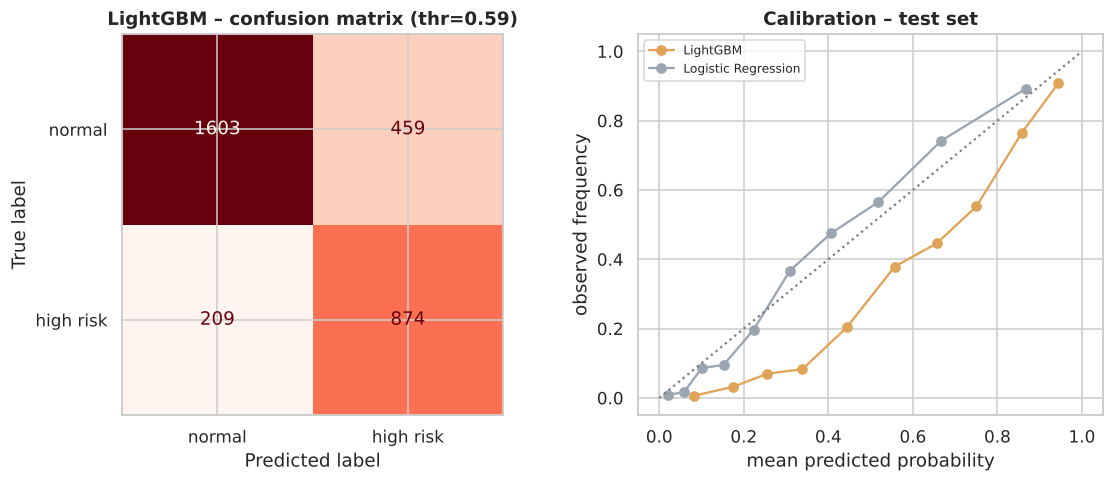

In [35]:
best_model = final_models[SELECTED]; p_best = test_pred[SELECTED]; thr_best = thresholds[SELECTED]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, p_best >= thr_best), display_labels=["normal", "high risk"]).plot(ax=axes[0], cmap="Reds", colorbar=False)
axes[0].set_title(f"{SELECTED} – confusion matrix (thr={thr_best:.2f})")
for n in [SELECTED, "Logistic Regression"]:
    fp, mp = calibration_curve(y_test, test_pred[n], n_bins=10, strategy="quantile")
    axes[1].plot(mp, fp, "o-", label=n, color=pal[n])
axes[1].plot([0, 1], [0, 1], ":", c="grey"); axes[1].set(xlabel="mean predicted probability", ylabel="observed frequency", title="Calibration – test set"); axes[1].legend(fontsize=8)
savefig("test_confusion_calibration"); plt.show()

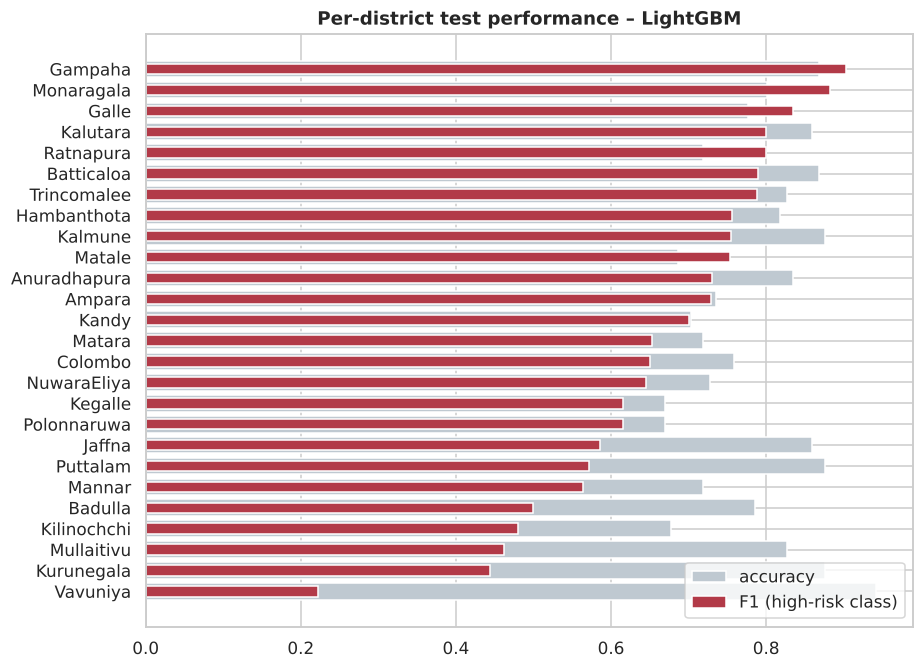

district,Vavuniya,Kurunegala,Mullaitivu,Kilinochchi,Badulla,Mannar,Puttalam,Jaffna,Polonnaruwa,Kegalle,...,Matale,Kalmune,Hambanthota,Trincomalee,Batticaloa,Ratnapura,Kalutara,Galle,Monaragala,Gampaha
positive rate,0.02,0.10,0.13,0.26,0.17,0.27,0.10,0.12,0.39,0.38,...,0.57,0.23,0.36,0.36,0.29,0.69,0.31,0.63,0.81,0.65
F1,0.22,0.44,0.46,0.48,0.50,0.56,0.57,0.59,0.62,0.62,...,0.75,0.75,0.76,0.79,0.79,0.80,0.80,0.83,0.88,0.90
Recall,0.50,0.50,0.56,0.58,0.65,0.67,0.83,0.86,0.68,0.70,...,0.84,0.82,0.79,0.89,0.86,0.81,0.89,0.89,0.92,0.94
Accuracy,0.94,0.88,0.83,0.68,0.79,0.72,0.88,0.86,0.67,0.67,...,0.69,0.88,0.82,0.83,0.87,0.72,0.86,0.78,0.80,0.87


In [36]:
test_eval = test.assign(p=p_best, pred=(p_best >= thr_best).astype(int))
per_d = test_eval.groupby("district").apply(lambda g: pd.Series({
    "positive rate": g["high_risk"].mean(),
    "F1": f1_score(g["high_risk"], g["pred"], zero_division=0),
    "Recall": recall_score(g["high_risk"], g["pred"], zero_division=0),
    "Accuracy": (g["high_risk"] == g["pred"]).mean()})).sort_values("F1")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(per_d.index, per_d["Accuracy"], color="#bfc9d1", label="accuracy")
ax.barh(per_d.index, per_d["F1"], color="#b23a48", height=.5, label="F1 (high-risk class)")
ax.set_title(f"Per-district test performance – {SELECTED}"); ax.legend(loc="lower right")
savefig("test_per_district"); plt.show()
display(per_d.round(2).T)

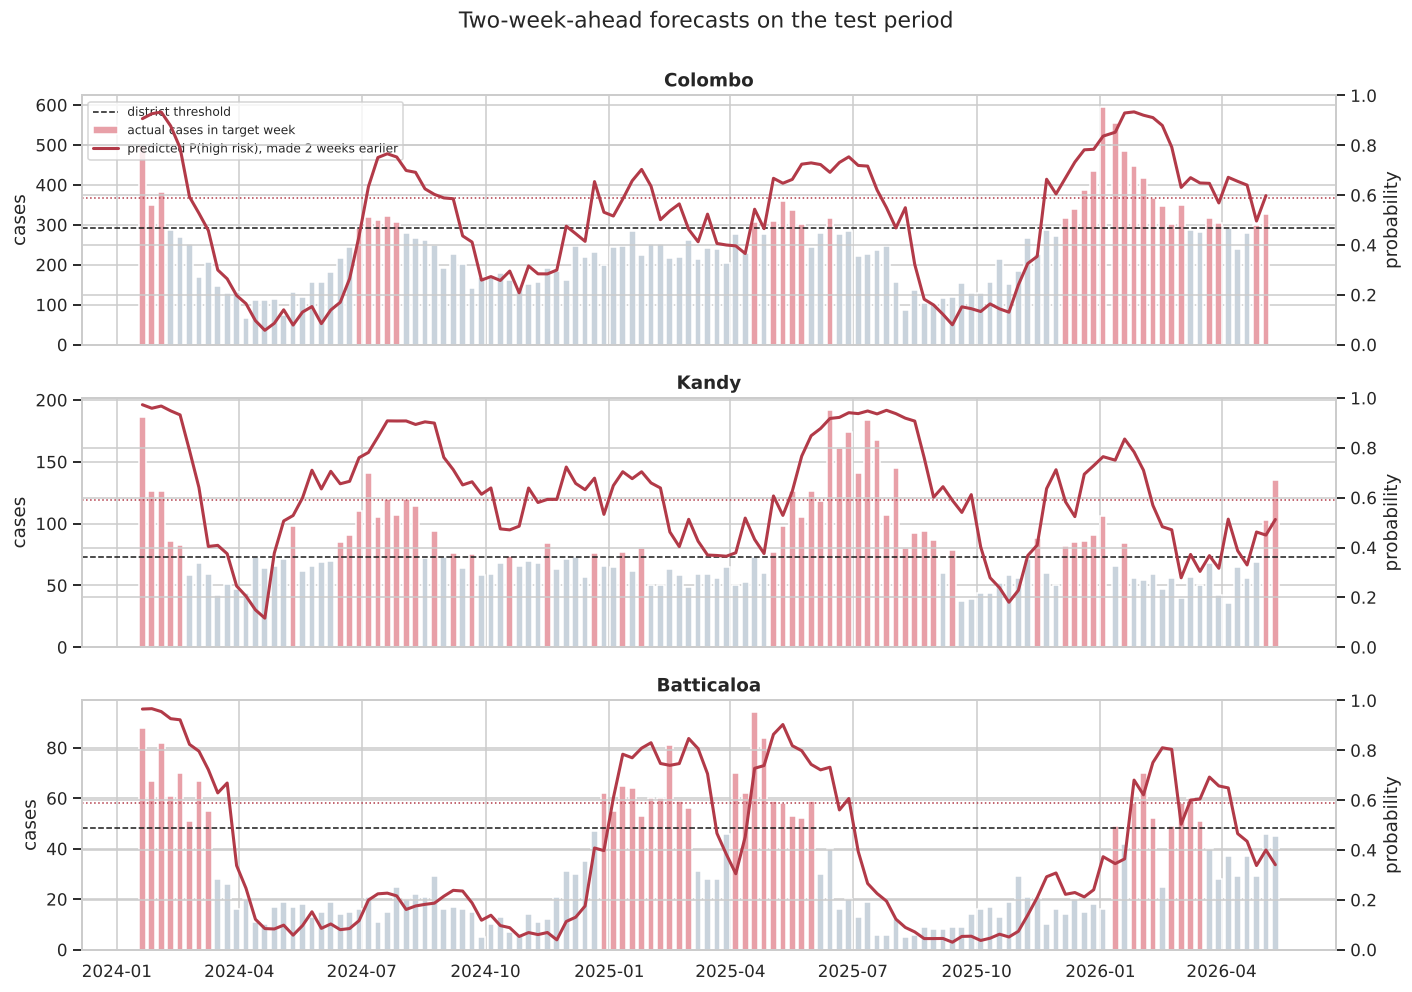

In [37]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, d in zip(axes, ["Colombo", "Kandy", "Batticaloa"]):
    g = test_eval[test_eval["district"] == d]
    ax.bar(g["target_date"], g["target_cases"], width=5, color=np.where(g["high_risk"] == 1, "#e8a0a8", "#c9d3dc"), label="actual cases in target week")
    ax.axhline(g["threshold"].iloc[0], c="k", ls="--", lw=1, label="district threshold")
    ax2 = ax.twinx(); ax2.plot(g["target_date"], g["p"], c="#b23a48", lw=2, label="predicted P(high risk), made 2 weeks earlier")
    ax2.axhline(thr_best, c="#b23a48", ls=":", lw=1); ax2.set_ylim(0, 1); ax2.set_ylabel("probability")
    ax.set_title(d); ax.set_ylabel("cases")
    if d == "Colombo":
        h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
fig.suptitle("Two-week-ahead forecasts on the test period", y=1.0); fig.tight_layout(); savefig("test_timelines"); plt.show()

### 11.1 Why LightGBM?

**Selection followed the rule fixed before testing.** LightGBM had the highest cross-validated PR-AUC on the shared 2020–23 folds (0.752). The stacking ensemble didn't beat it (−0.003), so the single model was kept. On the test set (Jan 2024 – May 2026) it scores:

| | ROC-AUC | PR-AUC | F1 | Precision | Recall | Bal. acc. |
|---|---|---|---|---|---|---|
| **LightGBM (selected)** | **0.877** | **0.791** | **0.724** | 0.656 | **0.807** | **0.792** |
| Persistence baseline | 0.772 | 0.592 | 0.700 | 0.695 | 0.706 | 0.772 |
| Seasonal naive | 0.585 | 0.394 | 0.472 | 0.442 | 0.506 | 0.585 |

**Why it's a suitable model for this problem**
1. **It clearly beats the strongest naive rule.** Persistence ("next is like now") is a tough baseline because dengue is autocorrelated. LightGBM improves PR-AUC by 0.20, with 95% bootstrap intervals that don't overlap (0.753–0.827 vs 0.547–0.635). It also raises **recall from 71% to 81%**, so about one in three outbreak weeks that persistence misses is now caught two weeks ahead. In 99.6% of bootstrap resamples its F1 is higher.
2. **It ranks risk well** (ROC-AUC 0.88), so health officials can prioritise districts by probability instead of relying on a yes/no flag.
3. **It suits small, noisy, shifting data.** The tuned model is very constrained: 4 leaves per tree, at least 206 samples per leaf and a low learning rate. That's a smooth, low-variance model, which matters when the positive rate swings between 7% and 82% from year to year.
4. **It's practical.** It trains in seconds, the saved file is 0.3 MB, and exact TreeSHAP explanations work in the app.

**Honest caveats**
* On the test set, CatBoost (PR-AUC 0.813) and the stacking ensemble (0.816) score slightly higher than LightGBM. Every tree model's 95% interval overlaps with the others, so their performance is statistically indistinguishable. Switching to the test winner now would be **selection on the test set**, so the pre-registered choice stands. The model comparison was decided by cross-validation and the test set only confirms generalisation.
* LightGBM was tuned with `scale_pos_weight ≈ 2.8`, so its **probabilities are inflated** (calibration plot: predicted 0.6 corresponds to roughly 0.4 observed). This doesn't affect ranking, and the CV-chosen decision threshold of 0.59 compensates. If calibrated probabilities were needed, isotonic calibration on the validation years would be the next step. Logistic regression is the best-calibrated model.
* Performance is lower in districts where high weeks are rare (Vavuniya, Kurunegala, Mullaitivu: F1 0.2–0.5). There, a few cases either way crosses the threshold. It's best in large, high-burden districts (Gampaha F1 0.90, Monaragala 0.88, Galle 0.83).

## 12. Explainability
### 12.1 SHAP (global and local)

In [38]:
# The model we explain: the selected one if it's a tree model; if the stack was selected we explain its strongest base learner
# with exact TreeSHAP and confirm with a model-agnostic permutation SHAP on the full stack.
explain_name = SELECTED if SELECTED != "Stacking (RF+XGB+LGBM+Cat → LR)" else best_single
explain_model = final_models[explain_name]
X_shap = X_test.sample(1500, random_state=SEED)
explainer = shap.TreeExplainer(explain_model)
sv = explainer(X_shap)
if sv.values.ndim == 3:   # (n, features, classes) for some tree models -> keep positive class
    sv = sv[:, :, 1]
SHAP_UNIT = "probability" if isinstance(explain_model, RandomForestClassifier) else "log-odds"
print("Explained model:", explain_name, f"| SHAP values are in {SHAP_UNIT} units of 'high risk'")

Explained model: LightGBM | SHAP values are in log-odds units of 'high risk'


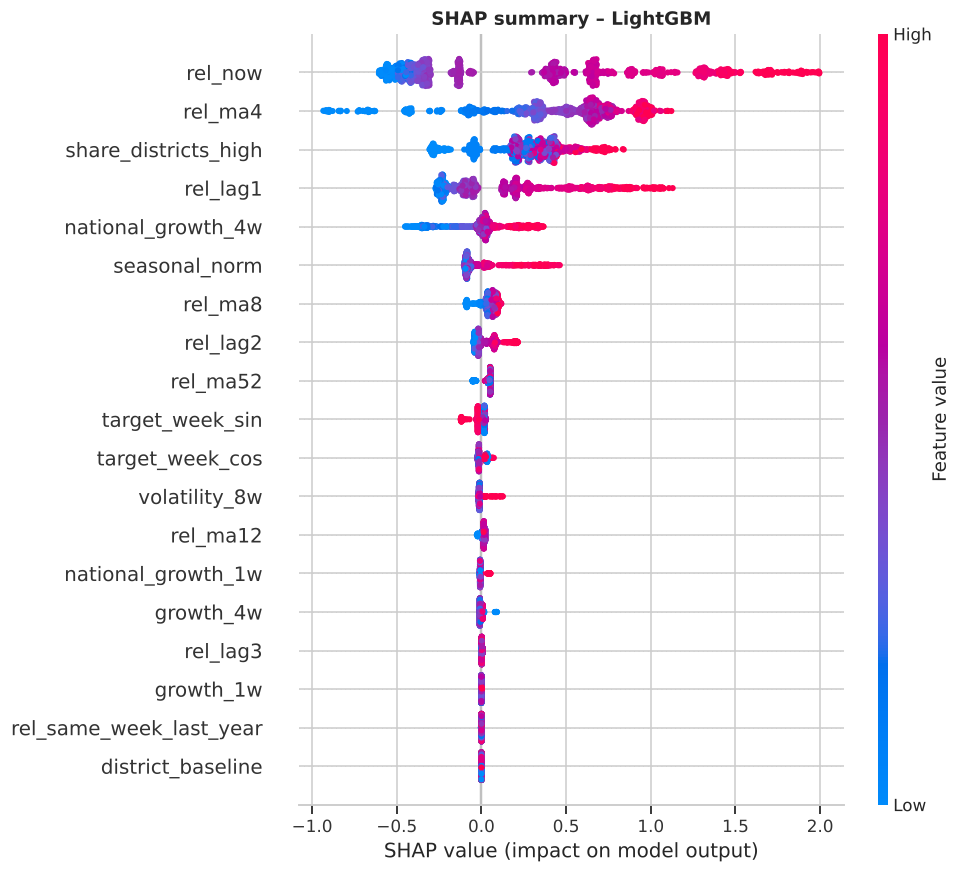

In [39]:
shap.plots.beeswarm(sv, max_display=19, show=False); plt.title(f"SHAP summary – {explain_name}"); savefig("shap_beeswarm"); plt.show()

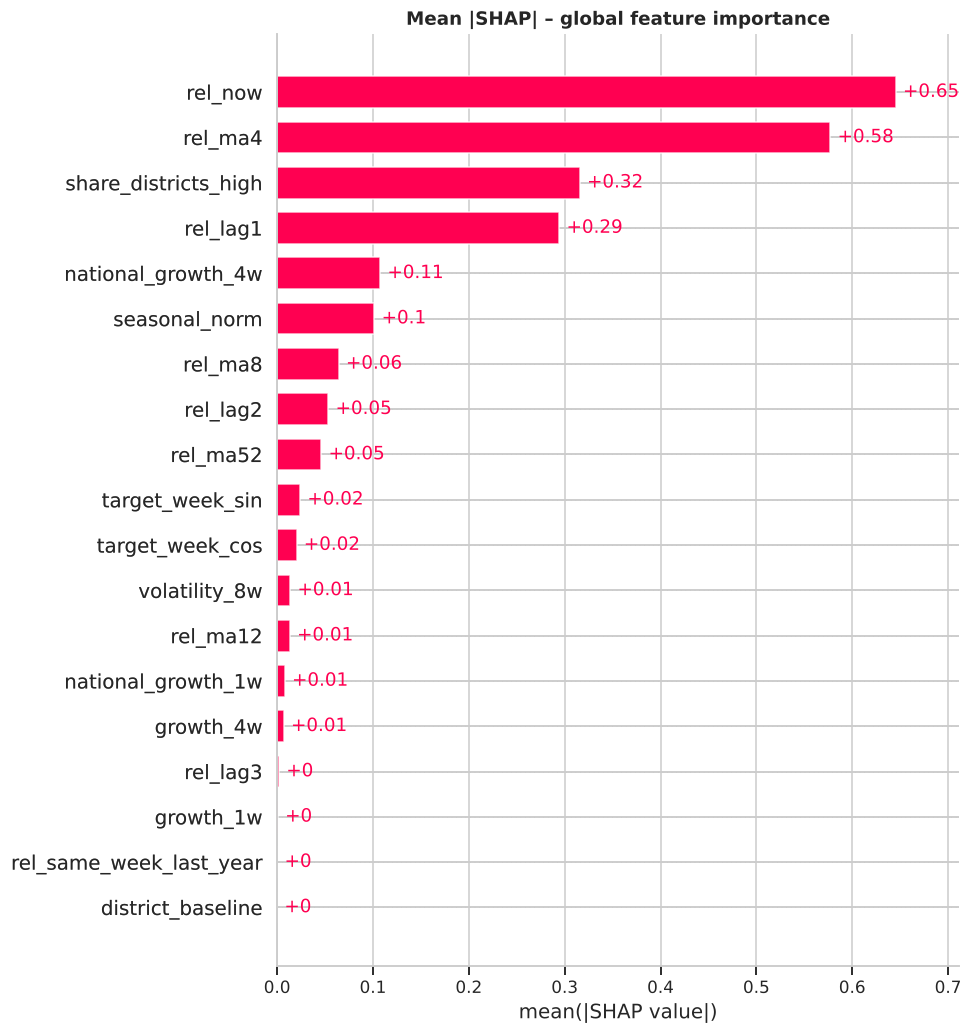

,rel_now,rel_ma4,share_districts_high,rel_lag1,national_growth_4w,seasonal_norm,rel_ma8,rel_lag2,rel_ma52,target_week_sin,target_week_cos,volatility_8w,rel_ma12,national_growth_1w,growth_4w,rel_lag3,growth_1w,rel_same_week_last_year,district_baseline
mean |SHAP|,0.645,0.577,0.316,0.294,0.108,0.101,0.064,0.053,0.046,0.024,0.02,0.014,0.013,0.008,0.007,0.002,0.001,0.0,0.0


In [40]:
shap.plots.bar(sv, max_display=19, show=False); plt.title("Mean |SHAP| – global feature importance"); savefig("shap_bar"); plt.show()
shap_imp = pd.Series(np.abs(sv.values).mean(0), index=FEATURES).sort_values(ascending=False)
display(shap_imp.round(3).to_frame("mean |SHAP|").T)

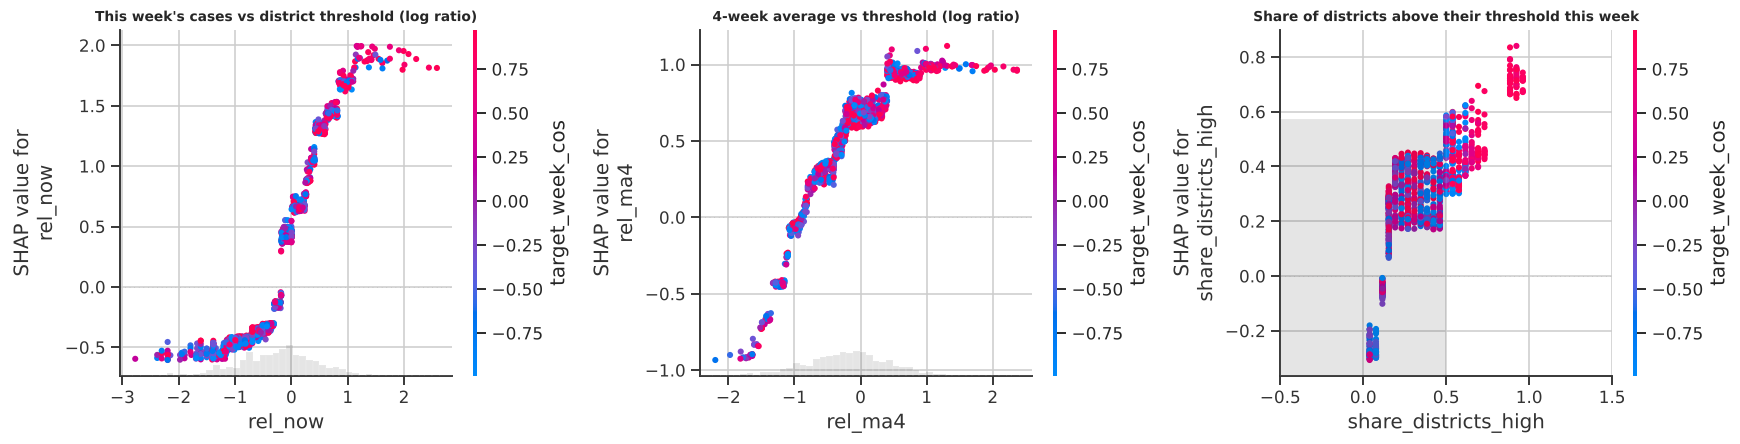

In [41]:
top3 = shap_imp.index[:3].tolist()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, f in zip(axes, top3):
    shap.plots.scatter(sv[:, f], color=sv[:, "target_week_cos" if f != "target_week_cos" else "rel_now"], ax=ax, show=False)
    ax.set_title(FEATURE_DESCRIPTIONS[f], fontsize=9)
plt.tight_layout(); savefig("shap_dependence"); plt.show()

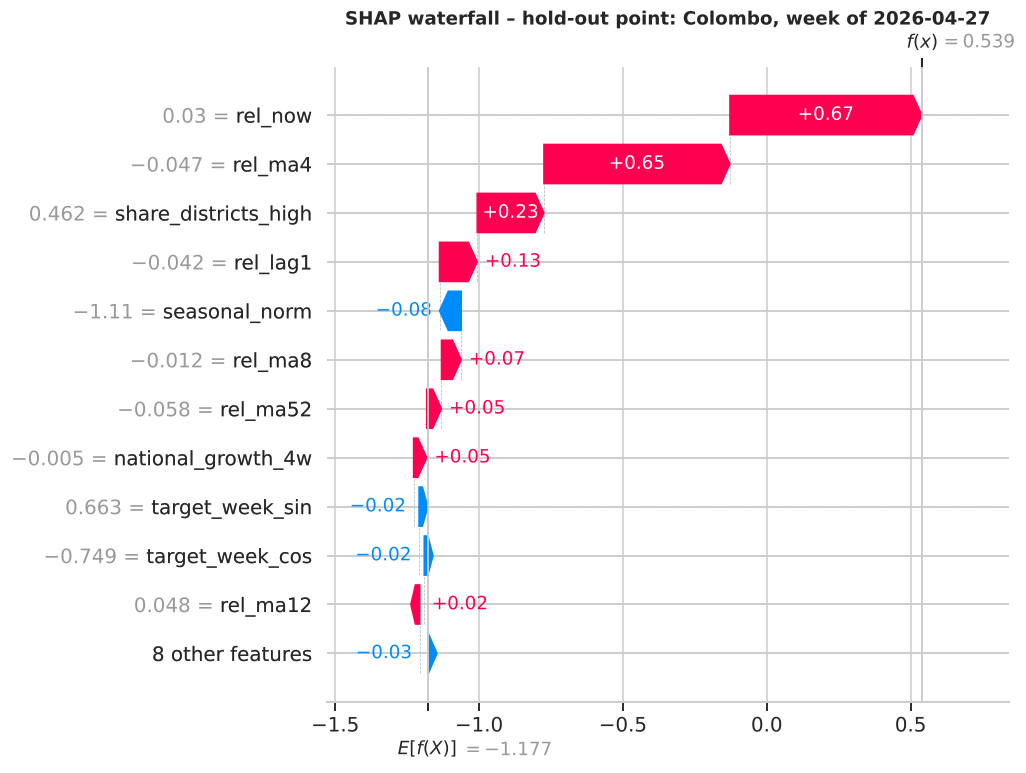

In [42]:
# local explanation for the hold-out data point
X_ho = holdout[FEATURES]
sv_ho = explainer(X_ho)
if sv_ho.values.ndim == 3: sv_ho = sv_ho[:, :, 1]
shap.plots.waterfall(sv_ho[0], max_display=12, show=False)
plt.title(f"SHAP waterfall – hold-out point: {holdout['district'].iloc[0]}, week of {holdout['date'].iloc[0].date()}")
savefig("shap_waterfall_holdout"); plt.show()

In [43]:
if SELECTED == "Stacking (RF+XGB+LGBM+Cat → LR)":
    bg = shap.sample(X_dev, 100, random_state=SEED)
    perm = shap.PermutationExplainer(lambda X: best_model.predict_proba(pd.DataFrame(X, columns=FEATURES))[:, 1], bg)
    sv_stack = perm(X_test.sample(300, random_state=SEED))
    stack_imp = pd.Series(np.abs(sv_stack.values).mean(0), index=FEATURES)
    print("Spearman rank correlation of importances (stack vs base learner):",
          round(stack_imp.rank().corr(shap_imp.reindex(FEATURES).rank()), 3))
    shap.plots.bar(sv_stack, max_display=12, show=False); plt.title("Permutation SHAP – full stacking ensemble"); plt.show()

### 12.2 LIME (local surrogate explanations)
LIME perturbs one instance, queries the model, and fits a weighted linear model around that point. We apply it to
(a) the hold-out point, (b) a correctly predicted outbreak onset, and (c) a missed outbreak, and we check how stable it is across random seeds.

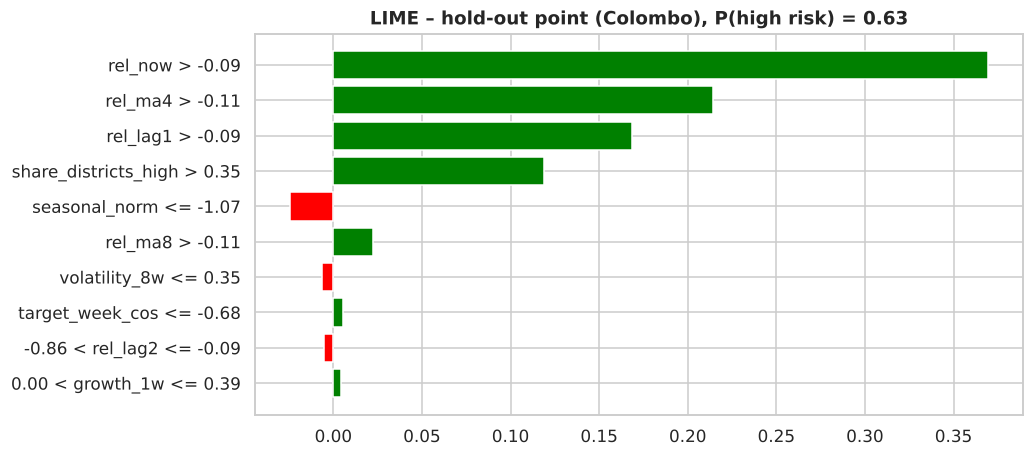

,condition,LIME weight
0,rel_now > -0.09,0.369
1,rel_ma4 > -0.11,0.214
2,rel_lag1 > -0.09,0.169
3,share_districts_high > 0.35,0.119
4,seasonal_norm <= -1.07,-0.024
5,rel_ma8 > -0.11,0.022
6,volatility_8w <= 0.35,-0.006
7,target_week_cos <= -0.68,0.006
8,-0.86 < rel_lag2 <= -0.09,-0.005
9,0.00 < growth_1w <= 0.39,0.005


In [44]:
predict_fn = lambda X: best_model.predict_proba(pd.DataFrame(X, columns=FEATURES))
lime_exp = lime.lime_tabular.LimeTabularExplainer(X_dev.values, feature_names=FEATURES, class_names=["normal", "high risk"],
                                                  mode="classification", discretize_continuous=True, random_state=SEED)
e_ho = lime_exp.explain_instance(X_ho.values[0], predict_fn, num_features=10, num_samples=5000)
fig = e_ho.as_pyplot_figure(label=1); fig.set_size_inches(9, 4.5)
plt.title(f"LIME – hold-out point ({holdout['district'].iloc[0]}), P(high risk) = {predict_fn(X_ho.values)[0,1]:.2f}")
savefig("lime_holdout"); plt.show()
display(pd.DataFrame(e_ho.as_list(label=1), columns=["condition", "LIME weight"]).round(3))

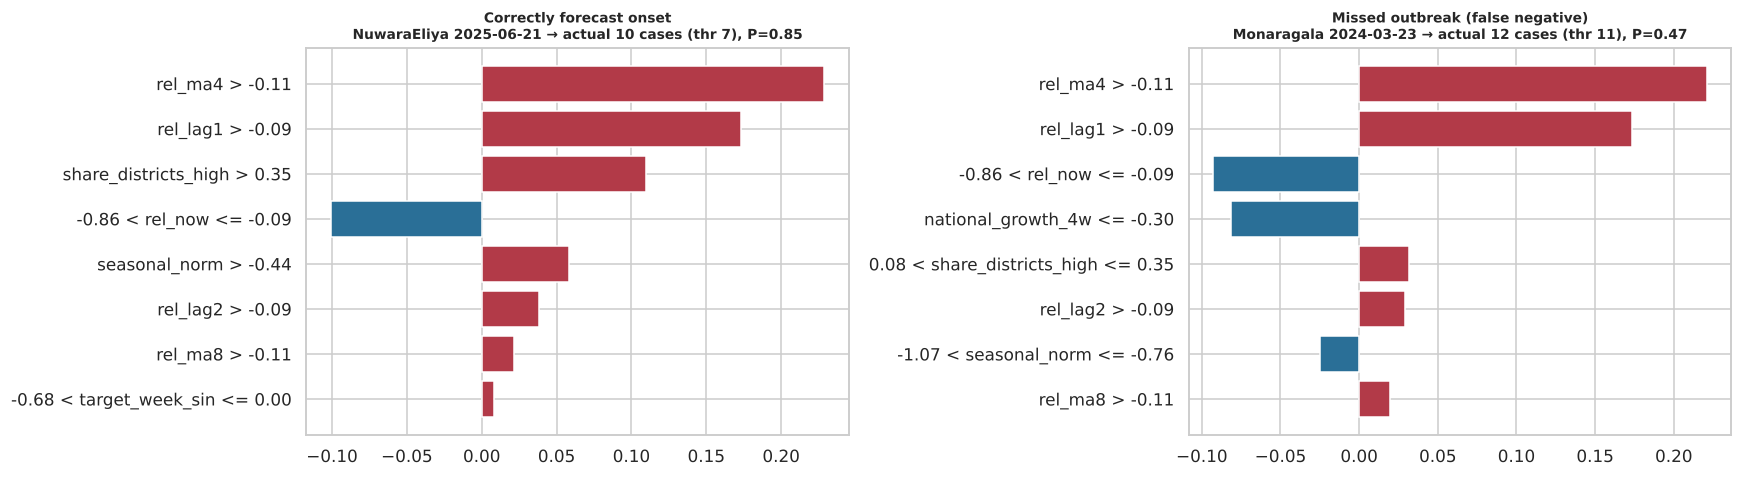

In [45]:
te = test_eval.assign(prev=(test_eval["rel_now"] > 0).astype(int))
onset_tp = te[(te["prev"] == 0) & (te["high_risk"] == 1) & (te["pred"] == 1)]
missed = te[(te["high_risk"] == 1) & (te["pred"] == 0)]
cases_lime = {"Correctly forecast onset": onset_tp.sort_values("p", ascending=False).iloc[0],
              "Missed outbreak (false negative)": missed.sort_values("p").iloc[len(missed) // 2]}
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, (lab, row) in zip(axes, cases_lime.items()):
    e = lime_exp.explain_instance(row[FEATURES].values.astype(float), predict_fn, num_features=8, num_samples=5000)
    items = e.as_list(label=1)[::-1]
    ax.barh([i[0] for i in items], [i[1] for i in items], color=["#b23a48" if i[1] > 0 else "#2a6f97" for i in items])
    ax.set_title(f"{lab}\n{row['district']} {row['date'].date()} → actual {int(row['target_cases'])} cases (thr {row['threshold']:.0f}), P={row['p']:.2f}", fontsize=9)
plt.tight_layout(); savefig("lime_cases"); plt.show()

In [46]:
# LIME stability: repeat for 5 seeds and compare the top-5 features selected
tops = []
for s in range(5):
    le = lime.lime_tabular.LimeTabularExplainer(X_dev.values, feature_names=FEATURES, class_names=["normal", "high risk"],
                                                mode="classification", discretize_continuous=True, random_state=s)
    ex = le.explain_instance(X_ho.values[0], predict_fn, num_features=5, num_samples=5000)
    tops.append(sorted([FEATURES[i] for i, _ in ex.as_map()[1]]))
print("Top-5 LIME features per seed:"); [print(" ", t) for t in tops]
print("Features in all 5 runs:", sorted(set.intersection(*map(set, tops))))

Top-5 LIME features per seed:
  ['rel_lag1', 'rel_ma4', 'rel_ma8', 'rel_now', 'share_districts_high']
  ['rel_lag1', 'rel_ma4', 'rel_now', 'seasonal_norm', 'share_districts_high']
  ['rel_lag1', 'rel_ma4', 'rel_ma8', 'rel_now', 'share_districts_high']
  ['rel_lag1', 'rel_ma4', 'rel_now', 'seasonal_norm', 'share_districts_high']
  ['rel_lag1', 'rel_ma4', 'rel_now', 'seasonal_norm', 'share_districts_high']
Features in all 5 runs: ['rel_lag1', 'rel_ma4', 'rel_now', 'share_districts_high']


In [47]:
# SHAP vs LIME agreement on the hold-out point
lime_w = pd.Series({FEATURES[i]: w for i, w in e_ho.as_map()[1]})
shap_w = pd.Series(sv_ho.values[0], index=FEATURES)
cmp = pd.DataFrame({"SHAP": shap_w, "LIME weight": lime_w}).dropna().sort_values("SHAP", key=abs, ascending=False)
cmp["same sign"] = np.sign(cmp["SHAP"]) == np.sign(cmp["LIME weight"])
display(cmp.round(3))
print(f"Sign agreement on LIME's top-10 features: {cmp['same sign'].mean():.0%}")

,SHAP,LIME weight,same sign
rel_now,0.667,0.369,True
rel_ma4,0.647,0.214,True
share_districts_high,0.232,0.119,True
rel_lag1,0.131,0.169,True
seasonal_norm,-0.076,-0.024,True
rel_ma8,0.069,0.022,True
target_week_cos,-0.018,0.006,False
volatility_8w,-0.012,-0.006,True
rel_lag2,-0.002,-0.005,True
growth_1w,-0.000,0.005,False


Sign agreement on LIME's top-10 features: 80%


### 12.3 Interpreting the model (SHAP + LIME)

**Global picture (SHAP beeswarm and bar).** The model works like an epidemiologist's rule of thumb, but with calibrated weights:
1. **`rel_now` and `rel_ma4`** (where this week and the last month sit relative to the district threshold) are by far the strongest drivers, with mean |SHAP| ≈ 0.6 log-odds each.
   The dependence plots show an **S-shaped response**. Below about −1 (cases under 40% of threshold) the push is a flat −0.5. It rises steeply between −0.5 and +1 and saturates once a district is clearly above threshold. The model has learned that **the zone just below the threshold is where the forecast is decided**.
2. **`share_districts_high`** is third. When more than half of Sri Lanka's districts are already above their thresholds, every district's risk rises (+0.4 to +0.8 log-odds). This captures **nationwide epidemic waves** like 2017, 2019 and 2023, which a single-district view can't see.
3. **`rel_lag1`, `national_growth_4w` and `seasonal_norm`** add momentum and seasonality. A rising national trend and a target week that is usually high (June–July after the SW monsoon, and December–January) both raise the risk.
4. **`district_baseline` and `rel_same_week_last_year` contribute almost nothing.** Once counts are scaled to each district's threshold, district size doesn't matter, and last year's level in the same week is a weak signal for this year. This is consistent with the seasonal-naive baseline doing poorly (PR-AUC 0.39).

**Local explanations.**
* **Hold-out point (Colombo, week of 27 Apr 2026, 300 cases vs threshold 291).** Starting from the base rate (−1.18 log-odds, about 24%), the forecast is pushed up by cases being right at threshold (`rel_now` +0.67), a 4-week average at threshold (`rel_ma4` +0.65) and 46% of districts being high nationally (+0.23). The seasonal norm pulls it down slightly (−0.08), because late May isn't usually a peak for Colombo. Final P = 0.63, which is above the 0.59 threshold, so it's predicted HIGH. The actual count was 308 cases, so the prediction was ✔.
* **LIME agrees.** On the hold-out point, LIME's top features are the same four (`rel_now`, `rel_ma4`, `share_districts_high`, `rel_lag1`), with the same signs as SHAP on 8 of LIME's 10 features. The two disagreements are on features with near-zero weight in both methods. Across 5 random seeds, LIME's top 5 always contained the same 4 core features, so the local explanation is **stable**.
* **Correctly forecast onset (Nuwara Eliya, June 2025).** This week was below threshold, which pushes the risk down. The recent 4-week average and last week were already near threshold, more than 35% of districts were high, and the target week was in the SW-monsoon season, so the model raised an alert two weeks before the district crossed its threshold.
* **Missed outbreak (Monaragala, March 2024, P = 0.47).** The national trend was falling (`national_growth_4w` ≤ −0.30) and this week was below threshold, so the model leaned towards "normal". The actual count was 12 against a threshold of 11, just over the line. Many errors are borderline cases like this one, where one or two cases decide the label.

**What this means in practice.** The model is transparent, and its logic is epidemiologically sensible: *recent level relative to normal, plus national momentum, plus season*. An MOH officer can read a SHAP waterfall and see why a district was flagged. The current gaps (no rainfall data, reporting noise) are visible in the explanations rather than hidden.

## 13. Save the model and run inference on the held-out data point

In [48]:
bundle = {
    "model": best_model,
    "model_name": SELECTED,
    "features": FEATURES,
    "feature_descriptions": FEATURE_DESCRIPTIONS,
    "decision_threshold": thr_best,
    "reference": ref,
    "horizon_weeks": HORIZON,
    "reference_years": REFERENCE_YEARS,
    "trained_on": f"{dev['date'].min().date()} to {dev['date'].max().date()} ({len(dev)} district-weeks)",
    "test_metrics": res.loc[SELECTED].drop("threshold").round(4).to_dict(),
    "best_params": best_params.get(SELECTED, {n: best_params[n] for n in stack_bases} if "Stacking" in SELECTED else {}),
}
joblib.dump(bundle, MODELS / "dengue_model.pkl")
meta = {k: v for k, v in bundle.items() if k not in ("model", "reference")}
json.dump(meta, open(MODELS / "model_metadata.json", "w"), indent=2, default=str)
df.drop(columns=["woy", "rel"]).to_csv(ROOT / "data" / "processed" / "dengue_weekly_clean.csv", index=False)
print("Saved:", MODELS / "dengue_model.pkl", f"({(MODELS / 'dengue_model.pkl').stat().st_size / 1e6:.1f} MB)")

Saved: /home/claude/dengue-early-warning/models/dengue_model.pkl (0.3 MB)


In [49]:
# --- fresh load, exactly as the app does ---
loaded = joblib.load(MODELS / "dengue_model.pkl")
ho = pd.read_csv(ROOT / "data" / "holdout_sample.csv", parse_dates=["date", "target_date"])
p_ho = loaded["model"].predict_proba(ho[loaded["features"]])[:, 1][0]
r = ho.iloc[0]
print(f"District           : {r['district']}")
print(f"Report week        : {r['date'].date()}  (cases this week = {int(r['cases'])})")
print(f"Forecast for week  : {r['target_date'].date()}  (threshold = {r['threshold']:.0f} cases)")
print(f"P(high risk)       : {p_ho:.3f}  -> predicted {'HIGH RISK' if p_ho >= loaded['decision_threshold'] else 'normal'} (decision threshold {loaded['decision_threshold']:.2f})")
print(f"Actual outcome     : {int(r['target_cases'])} cases -> {'HIGH RISK' if r['high_risk'] == 1 else 'normal'}")

District           : Colombo
Report week        : 2026-04-27  (cases this week = 300)
Forecast for week  : 2026-05-11  (threshold = 291 cases)
P(high risk)       : 0.632  -> predicted HIGH RISK (decision threshold 0.59)
Actual outcome     : 308 cases -> HIGH RISK


## 14. Conclusions, limitations and future work

**Summary.** Using 20 years of official Sri Lankan dengue surveillance data, I built a two-week-ahead early-warning classifier for all 26 RDHS areas.
After a careful EDA, three kinds of data problem were found and handled (a missing week, a year of zeros recorded instead of missing values for Monaragala, and 22 implausible or misaligned weekly values).
Nineteen leakage-free, scale-free features were engineered. Six model families were tuned with Optuna under expanding-window time-series cross-validation. The selected **LightGBM** model reaches **ROC-AUC 0.88, PR-AUC 0.79, recall 0.81** on 2½ years of unseen test data. It beats the persistence baseline by a statistically clear margin and provides explanations through SHAP and LIME that agree with each other.

**Requirement → where it's met**
* Problem and local data: §1–2 · EDA: §5 · Preprocessing (imputation, outliers, transformation, scaling, split): §6
* RF, XGBoost, LightGBM, CatBoost, LR and stacking: §8–10 · Tuning: §9 · Evaluation and justification: §11
* SHAP and LIME: §12 · Saved model and hold-out inference: §13 · App: `app/app.py` · MLOps: `src/train.py`, `tests/`, `.github/workflows/`

**Limitations**
* **No weather data.** District rainfall and temperature are known dengue drivers with a 2–8 week lag. They weren't available as an open district-weekly series, so seasonality and national momentum stand in for them.
* **Reported cases, not true infections.** Labels reflect testing and reporting behaviour, for example the COVID-19 disruption in 2020–21 and the data errors found here. Some errors may remain undetected.
* **Fixed thresholds.** The 75th percentile from 2012–2021 is one reasonable definition of "high transmission". Different thresholds (an epidemic channel, or mean + 2 SD) would change the task. The positive rate in the test period (34%) is higher than in training (20%), which reflects the post-2017 rise in dengue.
* **Probabilities aren't calibrated** (see §11.1). Treat them as risk scores.

**Future work**
1. Add weekly district rainfall (Department of Meteorology) and Breteau/larval indices from the NDCU.
2. Calibrate probabilities (isotonic regression on the validation years) and produce multi-horizon forecasts (1–4 weeks).
3. Use MOH-area (sub-district) data where available, for more targeted response.
4. Monitor live performance through the weekly retraining workflow, and re-estimate thresholds every few years.